# **Problem Statement**

## Context

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally and abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

## Objective

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications, a nine percent increase over the previous year. Reviewing every case is becoming a tedious task as the number of applicants increases every year.

The growing number of applicants calls for a machine learning based solution that can help shortlist candidates with higher chances of visa approval. OFLC has hired the firm EasyVisa for data-driven solutions. As a data scientist at EasyVisa, you must analyze the data provided and, with the help of a classification model:

1. Facilitate the process of visa approvals.
2. Recommend a suitable profile for applicants whose visa should be certified or denied, based on the drivers that significantly influence the case status.

## Data Description

The data contains attributes of the employee and the employer. The detailed data dictionary is given below.

* **case_id**: ID of each visa application
* **continent**: Information on the continent of the employee
* **education_of_employee**: Information on the education of the employee
* **has_job_experience**: Does the employee have any job experience? Y = Yes; N = No
* **requires_job_training**: Does the employee require any job training? Y = Yes; N = No
* **no_of_employees**: Number of employees in the employer's company
* **yr_of_estab**: Year in which the employer's company was established
* **region_of_employment**: Information on the foreign worker's intended region of employment in the US
* **prevailing_wage**: Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment
* **unit_of_wage**: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly
* **full_time_position**: Is the position of work full-time? Y = Full-Time Position; N = Part-Time Position
* **case_status**: Flag indicating whether the visa was certified or denied

## **Note: This is a sample solution for the project. Projects will NOT be graded on the basis of how well the submission matches this sample solution. Projects will be graded on the basis of the rubric only.**

# **Importing necessary libraries**

In [2]:
# %pip install -q --only-binary=:all: pandas==2.2.2 numpy==2.0.2 matplotlib==3.10.0 seaborn==0.13.2 scikit-learn==1.6.1

**Note**:
* After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
* On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in **this notebook**.

In [3]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Pre-processing and train-test split
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Model interpretation
from sklearn.inspection import permutation_importance

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Display settings: show all columns and show floats with 3 decimals
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Global plot style
sns.set_theme(style="whitegrid", palette="deep")

# Fixed seed so every split and model is reproducible
RANDOM_STATE = 42

# **Loading the dataset**

In [ ]:
# Uncomment to use Google Drive in Colab
# from google.colab import drive
# drive.mount('/content/drive')


In [5]:
# Read the dataset (see README to get EasyVisa.csv)
visa = pd.read_csv("data/EasyVisa.csv")

# Work on a copy so the original data stays untouched
data = visa.copy()

# **Overview of the Dataset**

#### First and last rows of the dataset

In [6]:
data.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.203,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,"83,425.650",Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,"122,996.860",Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,"83,434.030",Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,"149,907.390",Year,Y,Certified


In [7]:
data.tail()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,"77,092.570",Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,"279,174.790",Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,"146,298.850",Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,"86,154.770",Year,Y,Certified
25479,EZYV25480,Asia,Bachelor's,Y,N,3195,1960,Midwest,"70,876.910",Year,Y,Certified


#### Shape of the dataset

In [8]:
print(f"The dataset has {data.shape[0]:,} rows and {data.shape[1]} columns.")

The dataset has 25,480 rows and 12 columns.


#### Data types of the columns

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


#### Missing values and duplicates

In [10]:
# Missing values per column
data.isnull().sum()

,0
case_id,0
continent,0
education_of_employee,0
has_job_experience,0
requires_job_training,0
no_of_employees,0
yr_of_estab,0
region_of_employment,0
prevailing_wage,0
unit_of_wage,0


In [11]:
# Fully duplicated rows, and duplicated application IDs
print("Duplicated rows:", data.duplicated().sum())
print("Duplicated case_id values:", data["case_id"].duplicated().sum())

Duplicated rows: 0
Duplicated case_id values: 0


#### Statistical summary of the numerical columns

In [12]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_employees,"25,480.000","5,667.043","22,877.929",-26.000,"1,022.000","2,109.000","3,504.000","602,069.000"
yr_of_estab,"25,480.000","1,979.410",42.367,"1,800.000","1,976.000","1,997.000","2,005.000","2,016.000"
prevailing_wage,"25,480.000","74,455.815","52,815.942",2.137,"34,015.480","70,308.210","107,735.513","319,210.270"


#### Statistical summary of the categorical columns

In [13]:
data.describe(exclude="number").T

,count,unique,top,freq
case_id,25480,25480,EZYV25480,1
continent,25480,6,Asia,16861
education_of_employee,25480,4,Bachelor's,10234
has_job_experience,25480,2,Y,14802
requires_job_training,25480,2,N,22525
region_of_employment,25480,5,Northeast,7195
unit_of_wage,25480,4,Year,22962
full_time_position,25480,2,Y,22773
case_status,25480,2,Certified,17018


#### Categories and their frequencies

In [14]:
# Categorical columns (case_id is excluded because it is a unique identifier)
cat_cols = data.select_dtypes(exclude="number").columns.drop("case_id").tolist()

for col in cat_cols:
    print(data[col].value_counts())
    print("-" * 40)

continent
Asia             16861
Europe            3732
North America     3292
South America      852
Africa             551
Oceania            192
Name: count, dtype: int64
----------------------------------------
education_of_employee
Bachelor's     10234
Master's        9634
High School     3420
Doctorate       2192
Name: count, dtype: int64
----------------------------------------
has_job_experience
Y    14802
N    10678
Name: count, dtype: int64
----------------------------------------
requires_job_training
N    22525
Y     2955
Name: count, dtype: int64
----------------------------------------
region_of_employment
Northeast    7195
South        7017
West         6586
Midwest      4307
Island        375
Name: count, dtype: int64
----------------------------------------
unit_of_wage
Year     22962
Hour      2157
Week       272
Month       89
Name: count, dtype: int64
----------------------------------------
full_time_position
Y    22773
N     2707
Name: count, dtype: int64
--------

#### Sanity checks

In [15]:
# 1. A company cannot have zero or a negative number of employees
invalid_employees = data[data["no_of_employees"] <= 0]
print("Rows with no_of_employees <= 0:", len(invalid_employees))
print("Distinct invalid values:", sorted(invalid_employees["no_of_employees"].unique().tolist()))
print("Smallest positive value:", data.loc[data["no_of_employees"] > 0, "no_of_employees"].min())

Rows with no_of_employees <= 0: 33
Distinct invalid values: [-26, -25, -17, -14, -11]
Smallest positive value: 12


In [16]:
# 2. Year of establishment should not be in the future and should be plausible
print("Range of yr_of_estab:", data["yr_of_estab"].min(), "-", data["yr_of_estab"].max())
print("Companies established before 1900:", (data["yr_of_estab"] < 1900).sum())
print("Companies established exactly in 1800:", (data["yr_of_estab"] == 1800).sum())

Range of yr_of_estab: 1800 - 2016
Companies established before 1900: 2108
Companies established exactly in 1800: 16


In [17]:
# 3. prevailing_wage is reported in different units, so its scale should be checked per unit
data.groupby("unit_of_wage")["prevailing_wage"].describe()

,count,mean,std,min,25%,50%,75%,max
unit_of_wage,,,,,,,,
Hour,"2,157.000",414.571,275.015,2.137,152.700,372.652,637.311,999.919
Month,89.000,"87,592.864","59,525.125","1,599.280","44,986.240","81,826.010","121,629.600","264,362.950"
Week,272.000,"85,606.821","44,802.705","2,183.230","51,408.277","85,075.820","111,331.910","280,175.950"
Year,"22,962.000","81,228.077","49,951.473",100.000,"43,715.955","76,174.500","111,341.960","319,210.270"


**Observations**

* The dataset contains **25,480 visa applications** and **12 columns**: 3 numerical (`no_of_employees`, `yr_of_estab`, `prevailing_wage`) and 9 categorical (stored as text), including the target `case_status`.
* There are **no missing values** and **no duplicated rows**. Every `case_id` is unique, so it is only an identifier and carries no predictive information; it will be dropped before modeling.
* **Target:** 17,018 applications (66.8%) were **Certified** and 8,462 (33.2%) were **Denied**. The classes are moderately imbalanced (about 2:1), so accuracy alone can be misleading and the train-test split should be stratified.
* **Employee profile:** Asia dominates the applications (16,861, ~66%), followed by Europe and North America. Most applicants hold a Bachelor's (10,234) or Master's (9,634) degree, 58% have prior job experience, and only 12% require job training.
* **Employer / job profile:** the Northeast, South, and West receive most applications, while the Island region is very small (375). 89% of positions are full-time and 90% of wages are reported yearly.
* `no_of_employees` is **highly right-skewed**: the median is 2,109 but the mean is 5,667 and the maximum is 602,069 (very large corporations).
* `yr_of_estab` ranges from 1800 to 2016 (median 1997), so most sponsoring companies are relatively young.
* `prevailing_wage` ranges from 2.14 to 319,210 because it mixes hourly, weekly, monthly, and yearly units; it cannot be compared directly without considering `unit_of_wage`.

**Sanity checks**

* **Negative employees:** 33 rows have a negative `no_of_employees`. There is no zero, only five distinct values (-26, -25, -17, -14, -11), and the smallest positive value is 12. This pattern points to a **sign-entry error**, so the absolute value is a reasonable correction (treated in Data Pre-processing).
* **Year of establishment:** no company is established in the future. 2,108 companies were founded before 1900 and 16 exactly in 1800. Old companies are possible (many US firms are over 100 years old), so these values are kept, but the exact 1800 value may be a default placeholder.
* **Wage units:** hourly wages have a median of ~372.65 USD/hour, which is high for an hourly rate, while weekly and monthly wages have medians (~85,076 and ~81,826) on the **same scale as yearly wages**. This suggests the unit labels are not always consistent with the values, so converting everything to a yearly wage by multiplying would inflate these records. In line with the FAQ, `prevailing_wage` will **not** be converted; `unit_of_wage` will be kept as its own feature instead.

# **Exploratory Data Analysis (EDA)**

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Leading Questions**


1. What is the distribution of visa case statuses (certified vs. denied)?
2. How does the education level of employees impact visa approval rates?
3. Is there a significant difference in visa approval rates between employees with and without prior job experience?
4. How does the prevailing wage affect visa approval? Do higher wages lead to higher chances of approval?
5. Do certain regions in the US have higher visa approval rates compared to others?
6. How does the number of employees in a company influence visa approval? Do larger companies have a higher approval rate?
7. Are visa approval rates different across various continents of employees? Which continent has the highest and lowest approval rates?


**[IMPORTANT]** Beyond the Basics: Please note that these are guiding questions only. To receive full points for this rubric section, you are expected to perform a thorough analysis that goes beyond these specific questions to uncover deeper trends and relationships within the data.

## **Problem definition**

* **Business problem:** OFLC receives a growing number of visa applications every year and reviewing every case manually is slow. EasyVisa must help OFLC **shortlist applicants with a higher chance of approval** and explain **which applicant/employer characteristics drive certification or denial**.
* **Machine learning task:** binary classification. The target is `case_status` (**Certified** = 1, **Denied** = 0) and the predictors are the employee attributes (continent, education, job experience, job training) and the employer/job attributes (company size, year of establishment, region, prevailing wage, unit of wage, full-time position).
* **Goal of the EDA:** understand each variable, measure how the certification rate changes across the predictors, and identify the drivers that will later be confirmed by the models.

Throughout the notebook, **blue = Certified** and **orange = Denied**. The dashed line in the rate charts marks the overall certification rate (66.8%), so bars above it perform better than average.

### Helper functions for the EDA

The functions below are reused throughout the analysis so that all charts share the same style and colors.

In [18]:
# Fixed colors for the target classes (used in every chart of the notebook)
STATUS_ORDER = ["Certified", "Denied"]
STATUS_COLORS = {"Certified": "#2a78d6", "Denied": "#eb6834"}
NEUTRAL_COLOR = "#6b7a89"  # single-series charts that are not tied to a class

# Natural order of the education levels (lowest to highest)
EDUCATION_ORDER = ["High School", "Bachelor's", "Master's", "Doctorate"]

# Overall certification rate, used as a reference line in the rate charts
OVERALL_RATE = data["case_status"].eq("Certified").mean()


def histogram_boxplot(df, feature, log_scale=False, figsize=(12, 6)):
    """Boxplot (top) and histogram (bottom) of a numerical feature sharing the x-axis.
    The mean (dashed) and median (solid) are marked on the histogram."""
    fig, (ax_box, ax_hist) = plt.subplots(
        nrows=2, sharex=True, figsize=figsize, gridspec_kw={"height_ratios": (0.25, 0.75)}
    )
    sns.boxplot(x=df[feature], ax=ax_box, color=NEUTRAL_COLOR, showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"})
    sns.histplot(x=df[feature], ax=ax_hist, log_scale=log_scale, color=NEUTRAL_COLOR)
    ax_hist.axvline(df[feature].mean(), color="black", linestyle="--", linewidth=2,
                    label=f"Mean = {df[feature].mean():,.0f}")
    ax_hist.axvline(df[feature].median(), color="black", linestyle="-", linewidth=2,
                    label=f"Median = {df[feature].median():,.0f}")
    ax_hist.legend()
    ax_box.set_title(f"Distribution of {feature}" + (" (log scale)" if log_scale else ""), fontsize=14)
    plt.tight_layout()
    plt.show()


def labeled_barplot(df, feature, order=None, figsize=None):
    """Bar chart of the category counts, labeled with the percentage of each category."""
    order = order or df[feature].value_counts().index.tolist()
    plt.figure(figsize=figsize or (max(6, 1.4 * len(order)), 5))
    ax = sns.countplot(data=df, x=feature, order=order, color=NEUTRAL_COLOR)
    total = len(df)
    ax.bar_label(ax.containers[0], labels=[f"{h / total:.1%}" for h in ax.containers[0].datavalues], padding=3)
    ax.set_title(f"Distribution of {feature}", fontsize=14)
    ax.set_ylabel("Number of applications")
    ax.margins(y=0.1)
    plt.xticks(rotation=0 if len(order) < 6 else 30)
    plt.show()


def stacked_barplot(df, predictor, target="case_status", sort_by_rate=True):
    """Print the counts and certification rate per category, then plot a 100% stacked bar chart."""
    counts = pd.crosstab(df[predictor], df[target])[STATUS_ORDER]
    counts["Total"] = counts.sum(axis=1)
    counts["Certification rate"] = (counts["Certified"] / counts["Total"]).map("{:.1%}".format)
    rates = pd.crosstab(df[predictor], df[target], normalize="index")[STATUS_ORDER]
    if sort_by_rate:
        rates = rates.sort_values("Certified", ascending=False)
    display(counts.loc[rates.index])

    ax = rates.plot(kind="bar", stacked=True, figsize=(max(6, 1.4 * len(rates)), 5),
                    color=[STATUS_COLORS[s] for s in STATUS_ORDER], edgecolor="white", linewidth=2, width=0.7)
    # Label only the certification rate of each bar (the denied share is the complement)
    ax.bar_label(ax.containers[0], labels=[f"{v:.0%}" for v in rates["Certified"]],
                 label_type="center", color="white", fontweight="bold")
    ax.axhline(OVERALL_RATE, color="#52514e", linestyle="--", linewidth=1.5,
               label=f"Overall certification rate ({OVERALL_RATE:.1%})")
    ax.set_title(f"Case status by {predictor}", fontsize=14)
    ax.set_ylabel("Share of applications")
    ax.set_xlabel(predictor)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.xticks(rotation=0 if len(rates) < 6 else 30)
    plt.show()


def distribution_plot_wrt_target(df, predictor, target="case_status", log_scale=False):
    """Compare a numerical predictor across the two classes:
    density histogram per class, boxplot per class, and boxplot per class without outliers."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.histplot(data=df, x=predictor, hue=target, hue_order=STATUS_ORDER, palette=STATUS_COLORS,
                 stat="density", common_norm=False, element="step", log_scale=log_scale, ax=axes[0])
    axes[0].set_title(f"Density of {predictor} by {target}")
    for ax, show_outliers in zip(axes[1:], [True, False]):
        sns.boxplot(data=df, x=target, y=predictor, hue=target, order=STATUS_ORDER, hue_order=STATUS_ORDER,
                    palette=STATUS_COLORS, showfliers=show_outliers, log_scale=log_scale, legend=False, ax=ax)
        ax.set_title(f"{predictor} by {target}" + ("" if show_outliers else " (without outliers)"))
    plt.tight_layout()
    plt.show()


def certification_heatmap(df, row, col, row_order=None, col_order=None, target="case_status"):
    """Heatmap of the certification rate for every combination of two categorical variables."""
    table = (
        df.assign(certified=df[target].eq("Certified"))
        .pivot_table(index=row, columns=col, values="certified", aggfunc="mean", observed=True)
    )
    table = table.reindex(index=row_order or table.index, columns=col_order or table.columns)
    plt.figure(figsize=(max(6, 1.5 * table.shape[1]), max(4, 0.9 * table.shape[0])))
    ax = sns.heatmap(table, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, linewidths=2,
                     linecolor="white", cbar_kws={"label": "Certification rate", "format": plt.matplotlib.ticker.PercentFormatter(1.0)})
    ax.set_title(f"Certification rate by {row} and {col}", fontsize=14)
    plt.yticks(rotation=0)
    plt.show()

## **Univariate Analysis**

### Numerical variables

#### `no_of_employees`

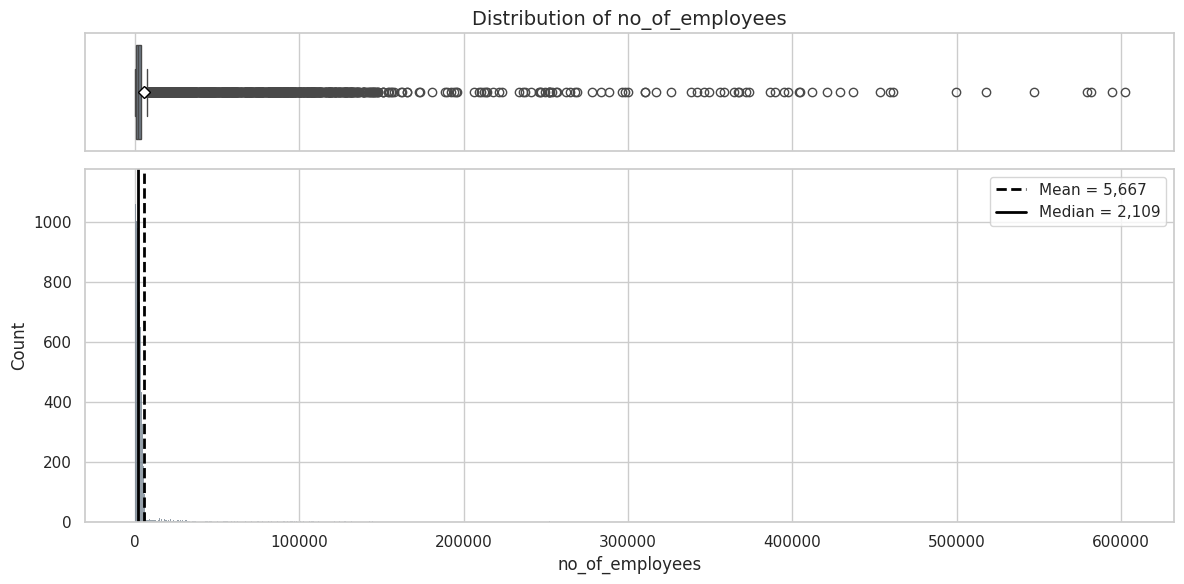

In [19]:
histogram_boxplot(data, "no_of_employees")

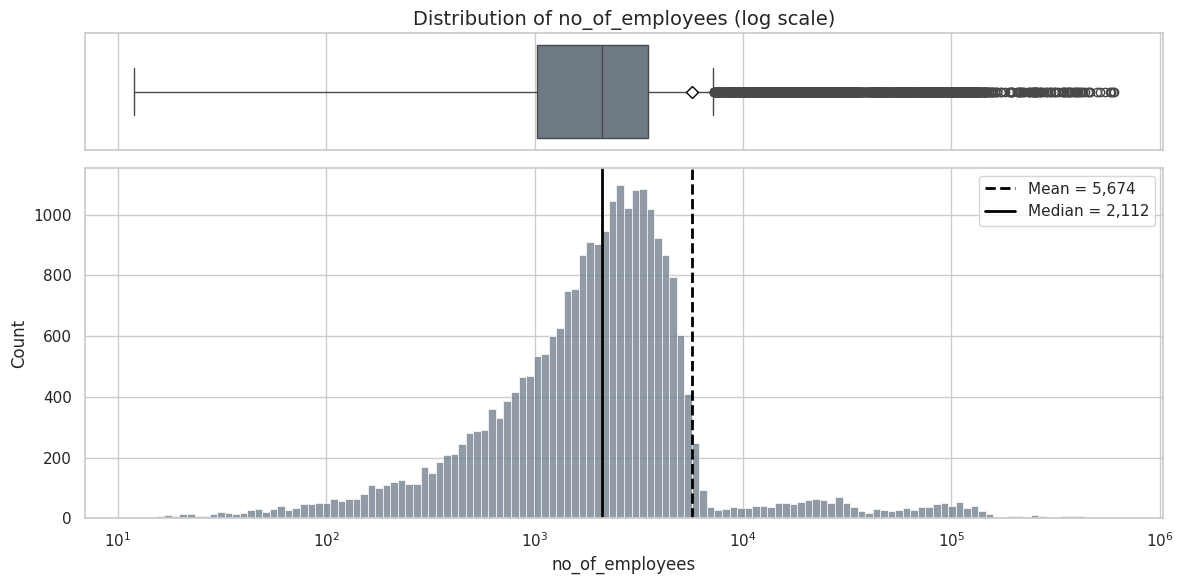

In [20]:
# The raw scale is dominated by a few very large companies, so the positive values are also shown on a log scale
histogram_boxplot(data[data["no_of_employees"] > 0], "no_of_employees", log_scale=True)

**Observations**
* `no_of_employees` is **extremely right-skewed** (a few corporations have up to 602,069 employees), so on the original scale almost all companies are squeezed near zero and the mean (5,667) is far above the median (2,109).
* On the log scale the distribution looks much more symmetric: half of the sponsoring companies have **between ~1,000 and ~3,500 employees**.
* The very large companies are genuine values (big multinational employers), not errors, so they are not treated as outliers to be removed. The 33 negative values are handled in Data Pre-processing.

#### `yr_of_estab`

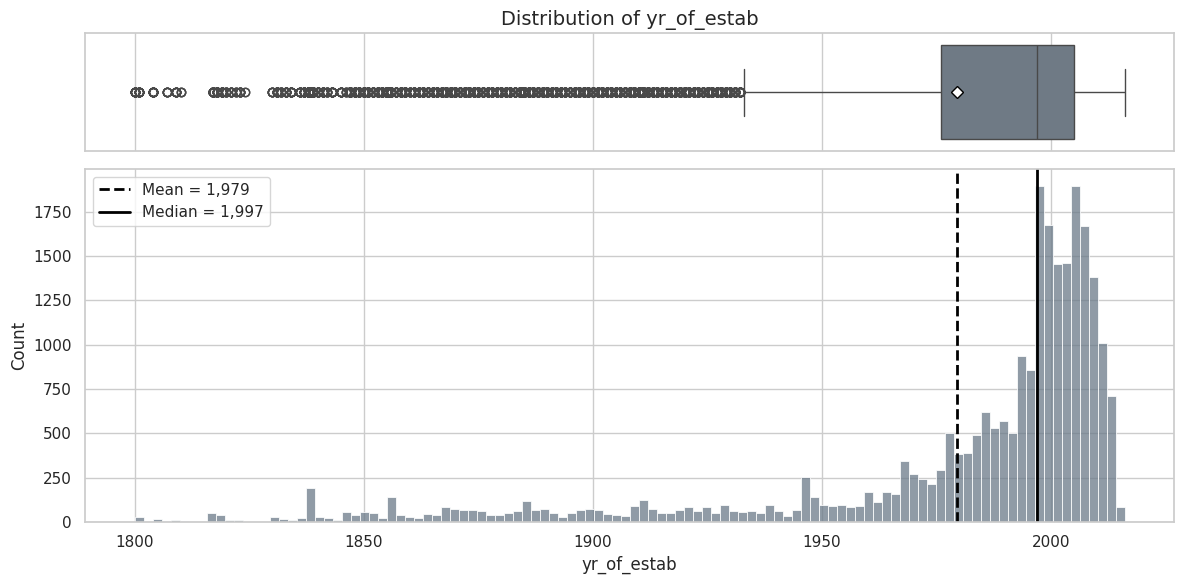

In [21]:
histogram_boxplot(data, "yr_of_estab")

**Observations**
* `yr_of_estab` is **left-skewed**: most companies were founded after 1976 (first quartile) and the median year is 1997, with a peak of companies founded in the 1990s-2000s.
* A long tail of old companies goes back to 1800. The boxplot flags them as outliers, but a company founded in the 1800s is plausible, so they are kept.

#### `prevailing_wage`

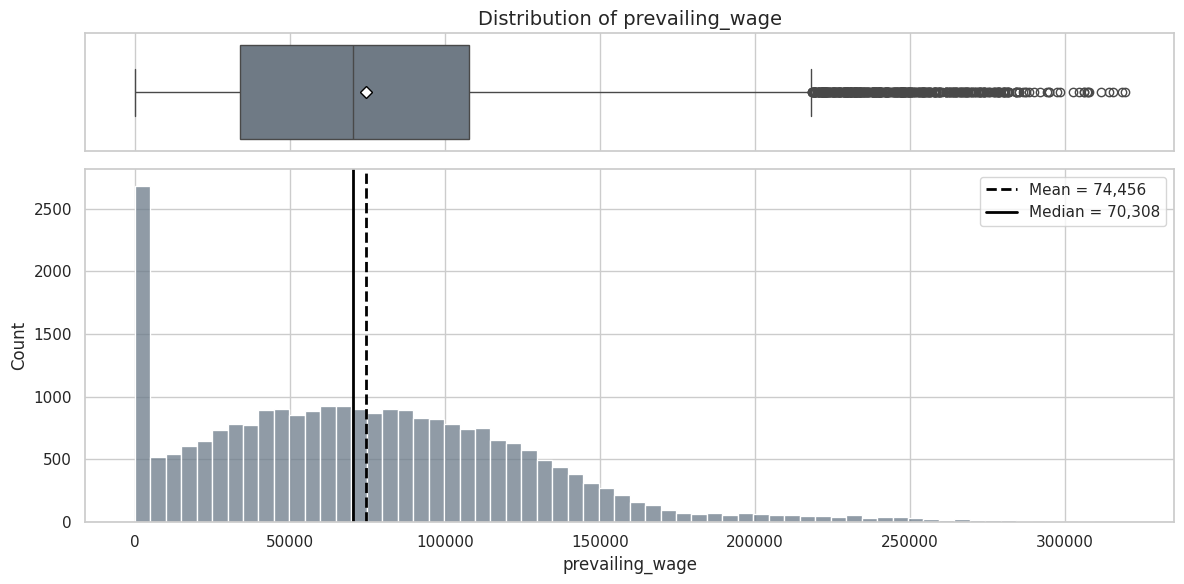

In [22]:
histogram_boxplot(data, "prevailing_wage")

**Observations**
* `prevailing_wage` is **right-skewed** with a median of ~70,308 and a mean of ~74,456.
* There is a clear **spike of very small values close to zero**: these are the hourly wages (median ~373), which live on a different scale from the weekly, monthly, and yearly wages.
* Most wages lie between ~34,000 and ~108,000 (interquartile range); high wages up to ~319,210 appear as outliers but are realistic for specialized positions.

### Categorical variables

#### Leading Question 1: What is the distribution of visa case statuses (certified vs. denied)?

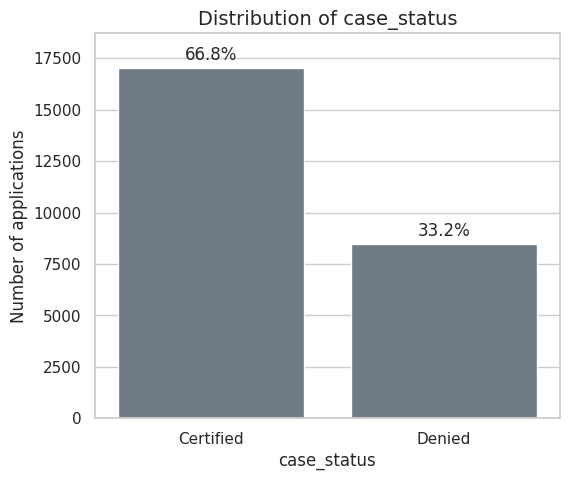

In [23]:
labeled_barplot(data, "case_status", order=STATUS_ORDER)

**Observations**
* **66.8% of the applications were certified** and **33.2% were denied**, so roughly 2 out of 3 applications are approved.
* The target is **moderately imbalanced**. A naive model that always predicts "Certified" would already reach ~67% accuracy, so accuracy alone is not enough to judge the models, and the train-test split must be stratified to keep this ratio in both sets.

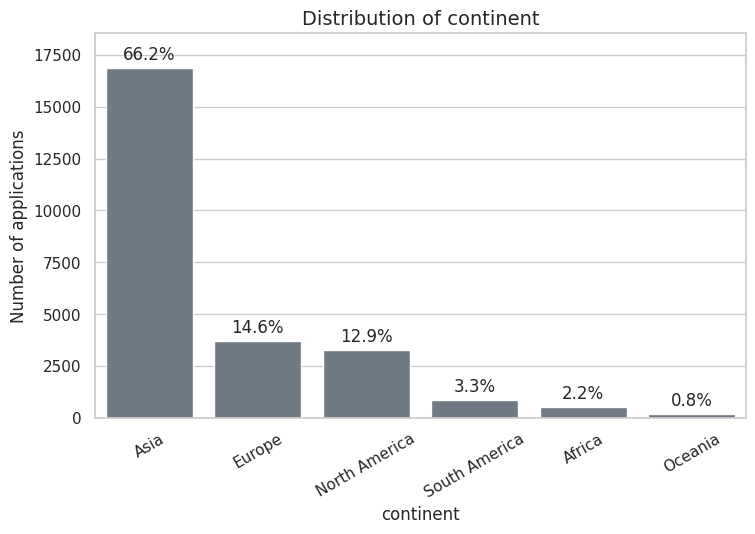

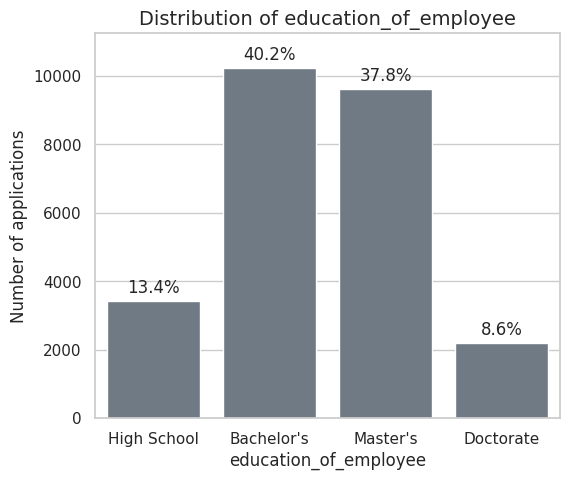

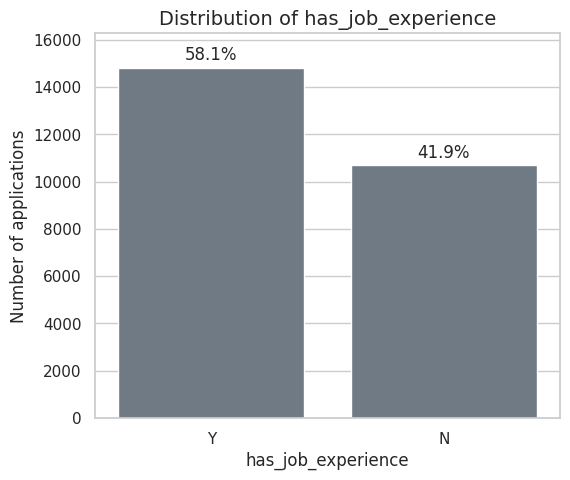

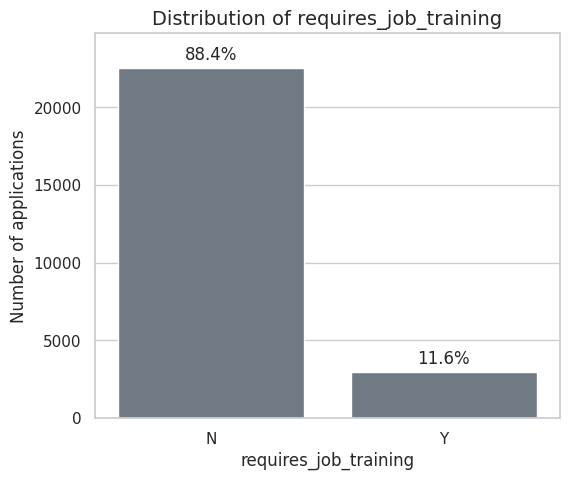

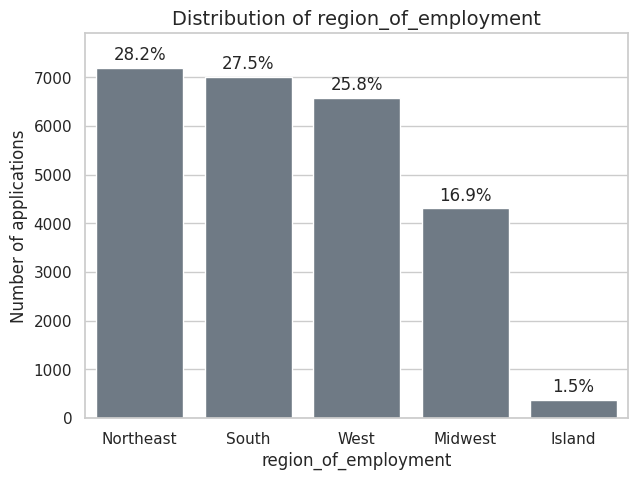

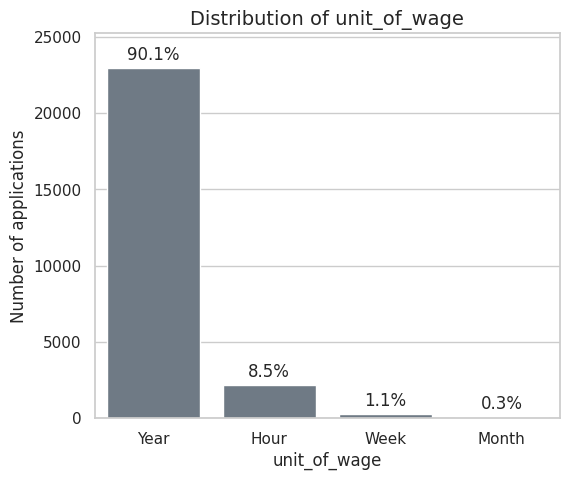

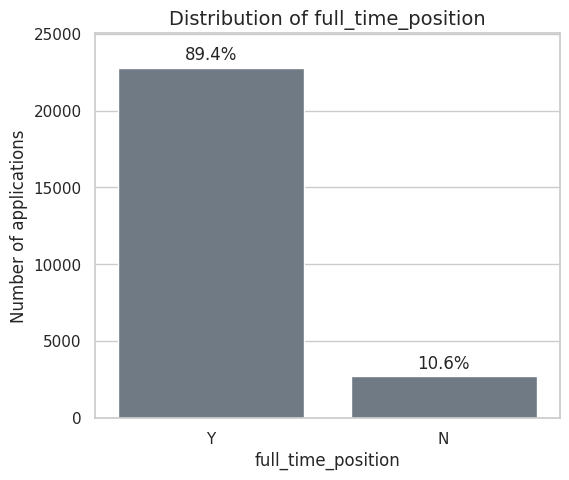

In [24]:
# Distribution of every categorical predictor
for col in ["continent", "education_of_employee", "has_job_experience", "requires_job_training",
            "region_of_employment", "unit_of_wage", "full_time_position"]:
    order = EDUCATION_ORDER if col == "education_of_employee" else None
    labeled_barplot(data, col, order=order)

**Observations**
* **continent:** Asia accounts for about two thirds of the applications (66.2%), followed by Europe (14.6%) and North America (12.9%). South America, Africa, and Oceania together are less than 7%.
* **education_of_employee:** the applicants are highly educated. Bachelor's (40.2%) and Master's (37.8%) degrees dominate, Doctorates are 8.6%, and only 13.4% have a High School education.
* **has_job_experience:** 58.1% of the applicants have prior job experience.
* **requires_job_training:** only 11.6% of the applicants require job training.
* **region_of_employment:** Northeast (28.2%), South (27.5%), and West (25.8%) receive most of the applications; Midwest has 16.9% and Island only 1.5%.
* **unit_of_wage:** 90.1% of the wages are yearly, 8.5% hourly, and weekly/monthly wages are very rare (1.1% and 0.3%).
* **full_time_position:** 89.4% of the positions are full-time.

## **Bivariate Analysis**

### Correlation between the numerical variables

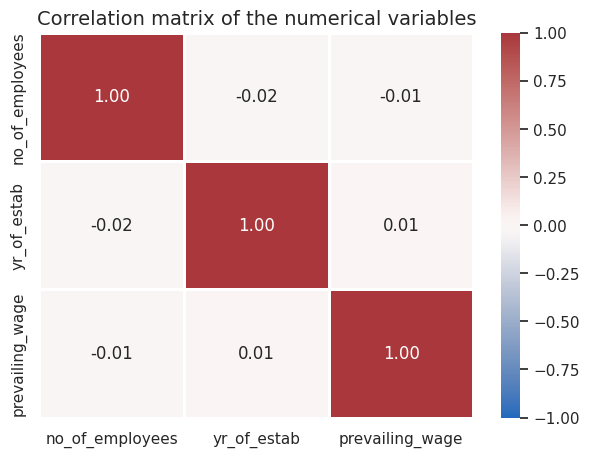

In [25]:
num_cols = ["no_of_employees", "yr_of_estab", "prevailing_wage"]

plt.figure(figsize=(7, 5))
sns.heatmap(data[num_cols].corr(), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
            linewidths=2, linecolor="white")
plt.title("Correlation matrix of the numerical variables", fontsize=14)
plt.show()

**Observations**
* The three numerical variables are **practically uncorrelated** (all correlations are between -0.02 and 0.01). There is no multicollinearity among them, and each one provides independent information.

#### Leading Question 2: How does the education level of employees impact visa approval rates?

case_status,Certified,Denied,Total,Certification rate
education_of_employee,,,,
Doctorate,1912,280,2192,87.2%
Master's,7575,2059,9634,78.6%
Bachelor's,6367,3867,10234,62.2%
High School,1164,2256,3420,34.0%


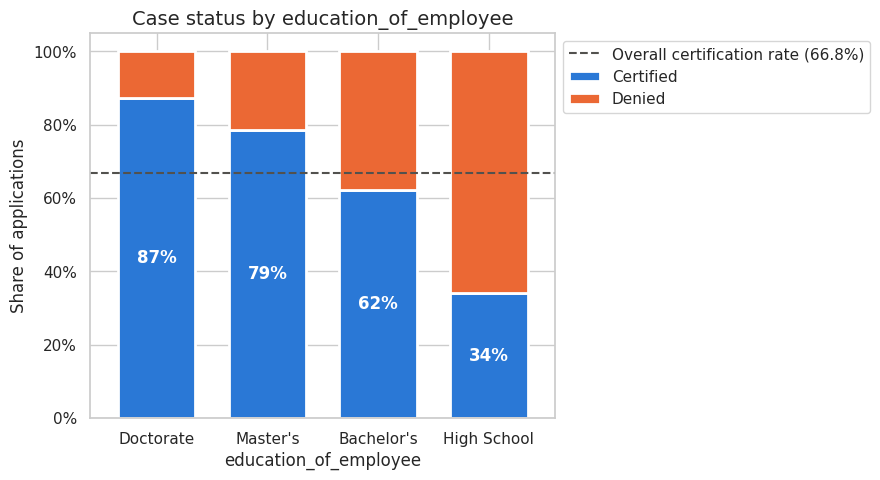

In [26]:
stacked_barplot(data, "education_of_employee")

**Observations**
* Education has the **strongest and most consistent effect** on approval: the certification rate increases with every level, from **34.0% for High School** to 62.2% for Bachelor's, 78.6% for Master's, and **87.2% for Doctorate**.
* High School applicants are the only group where **denials are more common than certifications** (66% denied).

#### Leading Question 3: Is there a significant difference in visa approval rates between employees with and without prior job experience?

case_status,Certified,Denied,Total,Certification rate
has_job_experience,,,,
Y,11024,3778,14802,74.5%
N,5994,4684,10678,56.1%


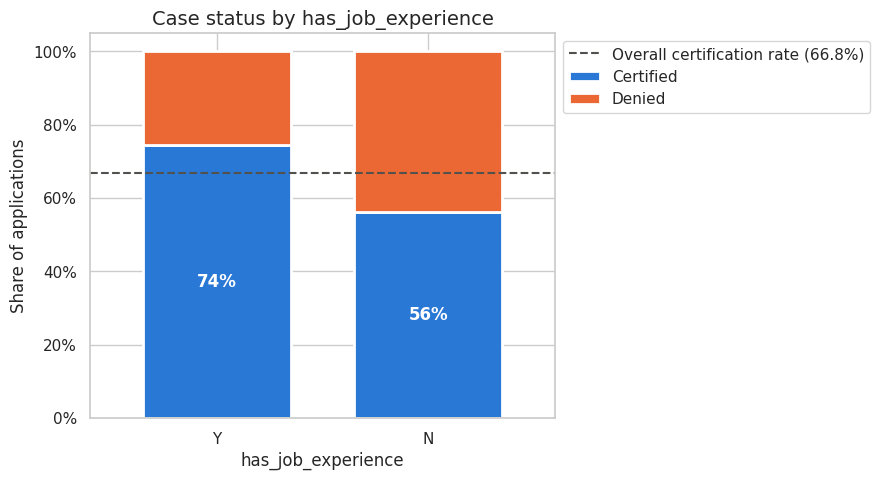

In [27]:
stacked_barplot(data, "has_job_experience")

**Observations**
* Yes. Applicants **with job experience are certified 74.5%** of the time versus **56.1% without experience**, a difference of about **18 percentage points**. With more than 10,000 applications in each group, this gap is large and not due to chance.

#### Leading Question 4: How does the prevailing wage affect visa approval? Do higher wages lead to higher chances of approval?

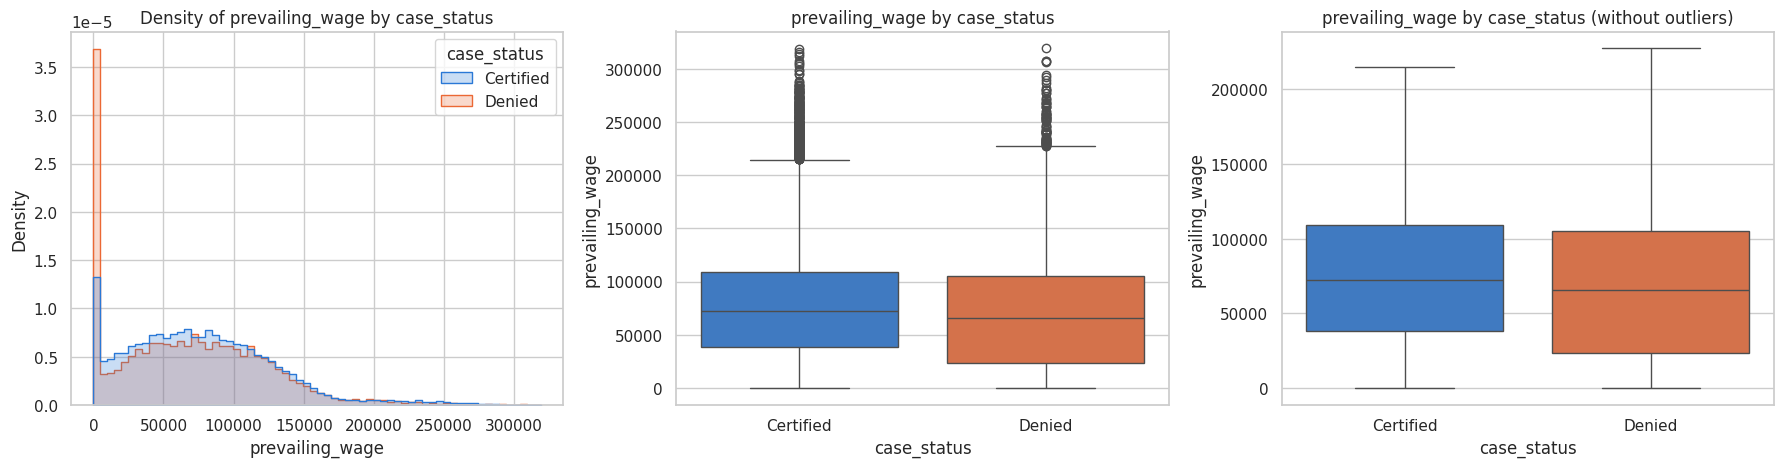

In [28]:
distribution_plot_wrt_target(data, "prevailing_wage")

Since `prevailing_wage` mixes different units, the relationship must also be checked **per unit of wage**.

case_status,Certified,Denied,Total,Certification rate
unit_of_wage,,,,
Year,16047,6915,22962,69.9%
Week,169,103,272,62.1%
Month,55,34,89,61.8%
Hour,747,1410,2157,34.6%


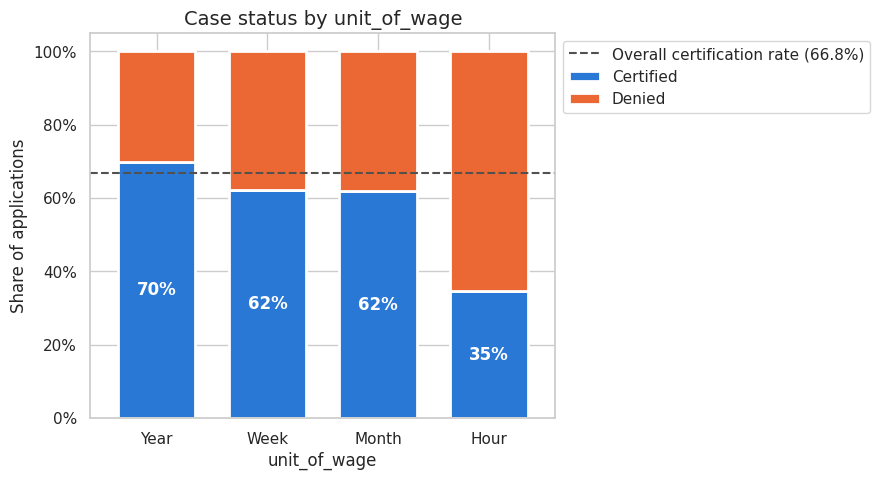

In [29]:
stacked_barplot(data, "unit_of_wage")

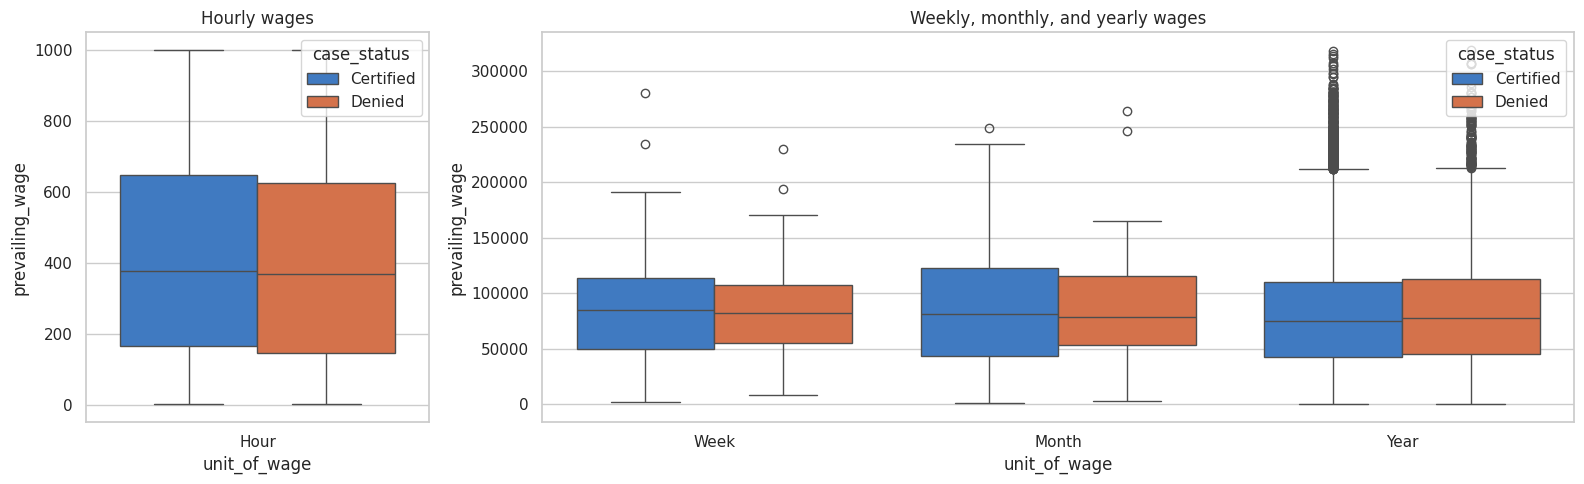

In [30]:
# Prevailing wage by case status for each unit of wage
# (hourly wages are plotted separately because they are on a much smaller scale)
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": (1, 3)})
hourly = data["unit_of_wage"] == "Hour"
sns.boxplot(data=data[hourly], x="unit_of_wage", y="prevailing_wage", hue="case_status",
            hue_order=STATUS_ORDER, palette=STATUS_COLORS, ax=axes[0])
sns.boxplot(data=data[~hourly], x="unit_of_wage", y="prevailing_wage", hue="case_status",
            order=["Week", "Month", "Year"], hue_order=STATUS_ORDER, palette=STATUS_COLORS, ax=axes[1])
axes[0].set_title("Hourly wages")
axes[1].set_title("Weekly, monthly, and yearly wages")
for ax in axes:
    ax.legend(title="case_status", loc="upper right")
plt.tight_layout()
plt.show()

case_status,Certified,Denied,Total,Certification rate
wage_quartile,,,,
Q1 (lowest),4108,1633,5741,71.6%
Q2,4007,1733,5740,69.8%
Q3,3989,1751,5740,69.5%
Q4 (highest),3943,1798,5741,68.7%


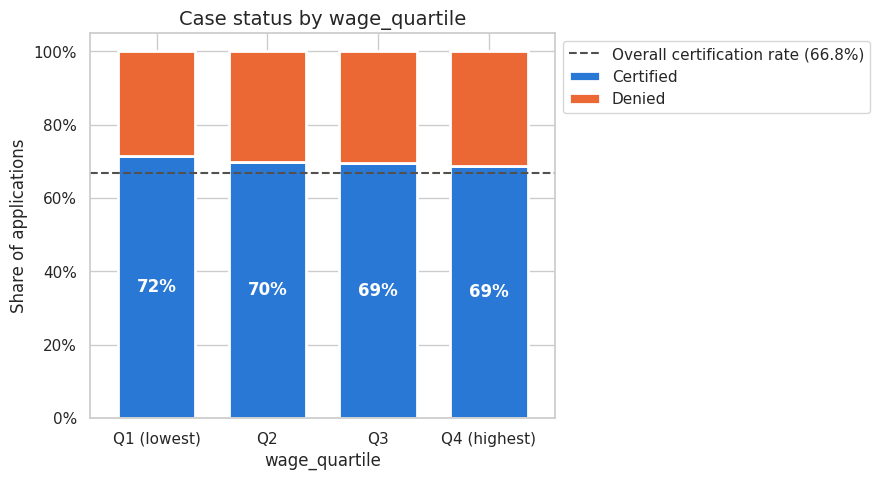

In [31]:
# Among yearly wages only (90% of the data), does a higher wage increase the certification rate?
yearly = data[data["unit_of_wage"] == "Year"].copy()
yearly["wage_quartile"] = pd.qcut(yearly["prevailing_wage"], q=4,
                                  labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
stacked_barplot(yearly, "wage_quartile", sort_by_rate=False)

**Observations**
* At first sight, certified applications have a higher median wage (~72,486) than denied ones (~65,431), and the denied group has more mass at very low values.
* However, this difference is explained almost entirely by the **unit of wage**: **hourly-paid positions are certified only 34.6%** of the time, compared with 69.9% for yearly wages (weekly and monthly are around 62%). Hourly positions are typically contractual or entry-level jobs, and they are the ones with very low `prevailing_wage` values.
* Within the same unit, the wage distributions of certified and denied cases **almost completely overlap**. Among yearly wages, the certification rate is practically flat across the wage quartiles (71.6% in the lowest quartile vs 68.7% in the highest).
* **Conclusion:** a higher wage by itself does **not** lead to a higher chance of approval; what matters is **how the job is paid** (yearly salaried position vs hourly). The weekly and monthly wages have medians (~85,000) on the same scale as yearly wages, which confirms that the wage column should not be converted by simply multiplying by the unit.

#### Leading Question 5: Do certain regions in the US have higher visa approval rates compared to others?

case_status,Certified,Denied,Total,Certification rate
region_of_employment,,,,
Midwest,3253,1054,4307,75.5%
South,4913,2104,7017,70.0%
Northeast,4526,2669,7195,62.9%
West,4100,2486,6586,62.3%
Island,226,149,375,60.3%


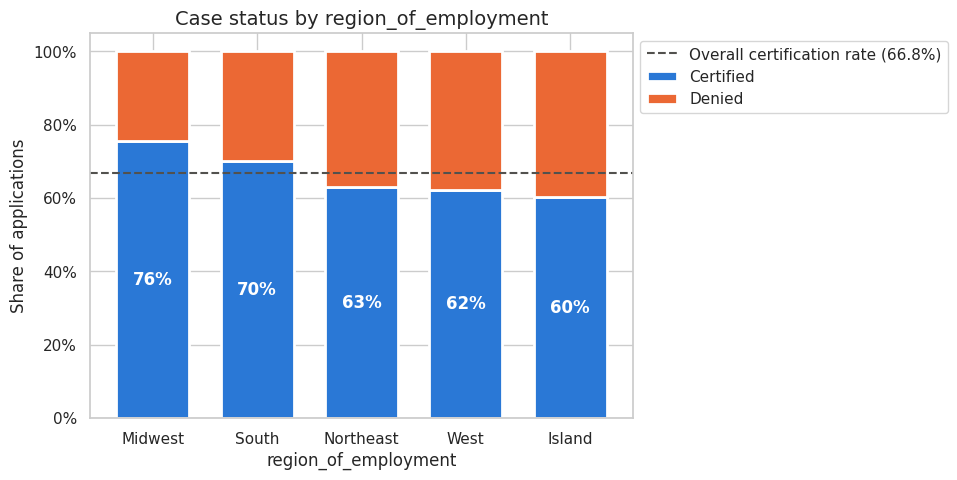

In [32]:
stacked_barplot(data, "region_of_employment")

**Observations**
* Yes. The **Midwest has the highest certification rate (75.5%)**, followed by the South (70.0%). Both are above the overall rate.
* The Northeast (62.9%), West (62.3%), and Island (60.3%) regions are below the average, even though the Northeast and West receive a large share of the applications.
* The region effect (~15 percentage points between best and worst) is smaller than the education and job-experience effects.

#### Leading Question 6: How does the number of employees in a company influence visa approval? Do larger companies have a higher approval rate?

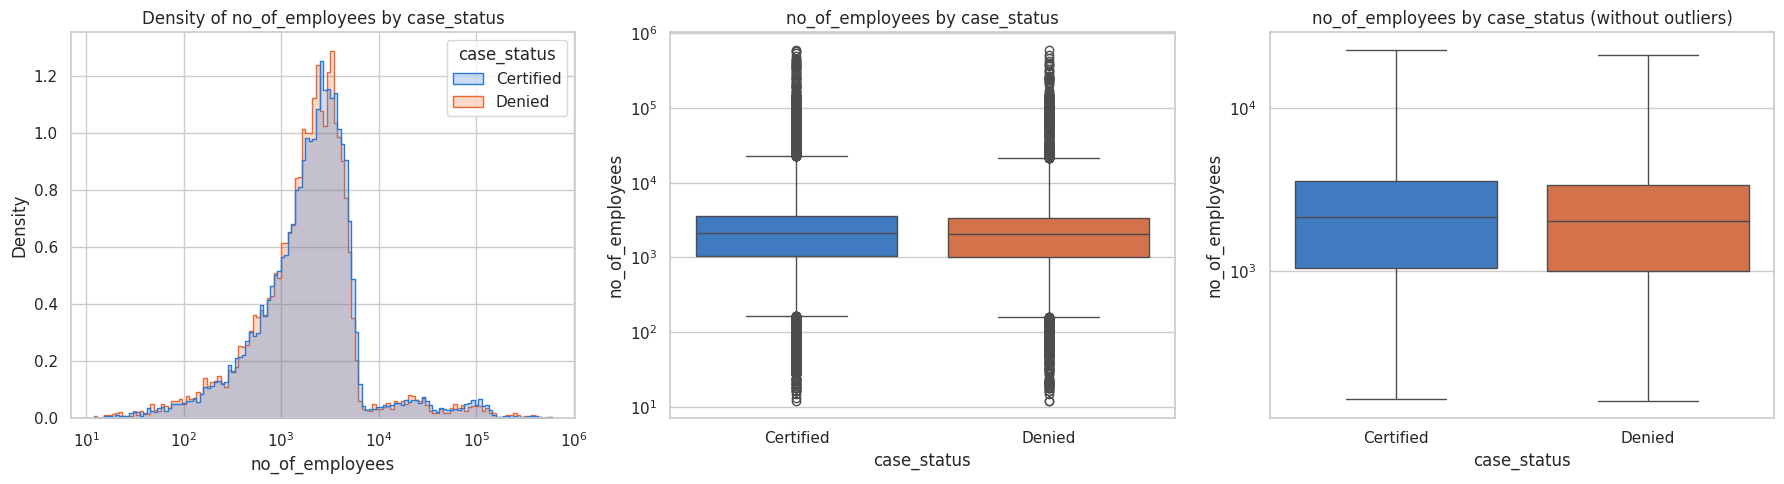

In [33]:
distribution_plot_wrt_target(data[data["no_of_employees"] > 0], "no_of_employees", log_scale=True)

case_status,Certified,Denied,Total,Certification rate
company_size,,,,
<=100,351,215,566,62.0%
101-500,1663,872,2535,65.6%
501-1K,2094,1046,3140,66.7%
1K-2K,3878,2037,5915,65.6%
2K-5K,7174,3513,10687,67.1%
5K-10K,875,326,1201,72.9%
>10K,983,453,1436,68.5%


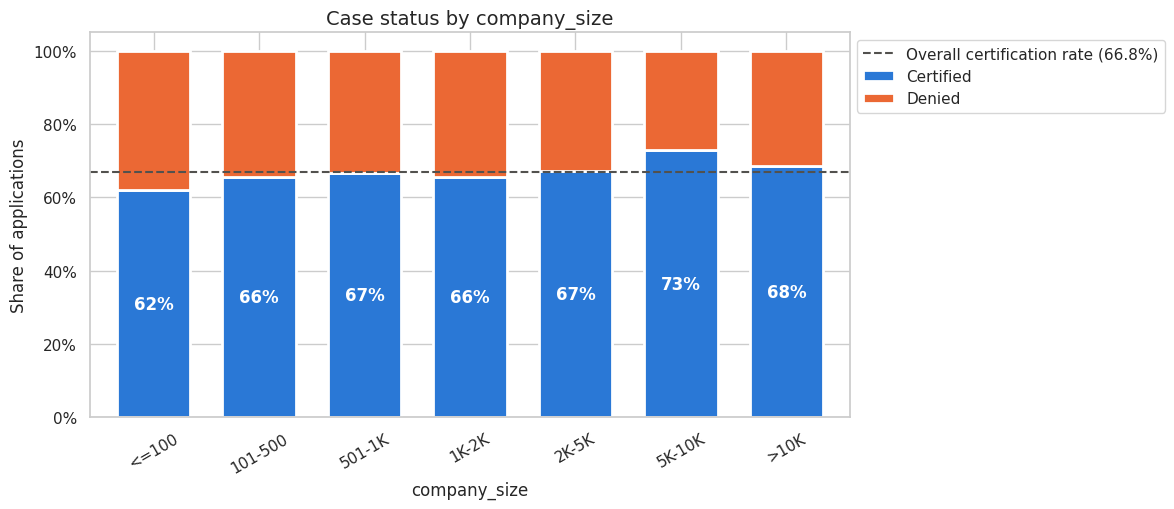

In [34]:
# Group the companies into size bands to compare their certification rates
size_labels = ["<=100", "101-500", "501-1K", "1K-2K", "2K-5K", "5K-10K", ">10K"]
company_sizes = data.assign(
    company_size=pd.cut(data["no_of_employees"], bins=[-np.inf, 100, 500, 1000, 2000, 5000, 10000, np.inf],
                        labels=size_labels)
)
stacked_barplot(company_sizes, "company_size", sort_by_rate=False)

**Observations**
* The distributions of `no_of_employees` for certified and denied cases are **almost identical** (median ~2,147 vs ~2,033 employees).
* The certification rate increases only slightly with company size, from 62.0% for companies with at most 100 employees to a peak of 72.9% for companies with 5K-10K employees, and it drops again to 68.5% for the largest companies (>10K).
* **Conclusion:** larger companies have a **slightly** higher approval rate, but the company size is a **weak driver** of the case status compared with the applicant's profile.

#### Leading Question 7: Are visa approval rates different across various continents of employees? Which continent has the highest and lowest approval rates?

case_status,Certified,Denied,Total,Certification rate
continent,,,,
Europe,2957,775,3732,79.2%
Africa,397,154,551,72.1%
Asia,11012,5849,16861,65.3%
Oceania,122,70,192,63.5%
North America,2037,1255,3292,61.9%
South America,493,359,852,57.9%


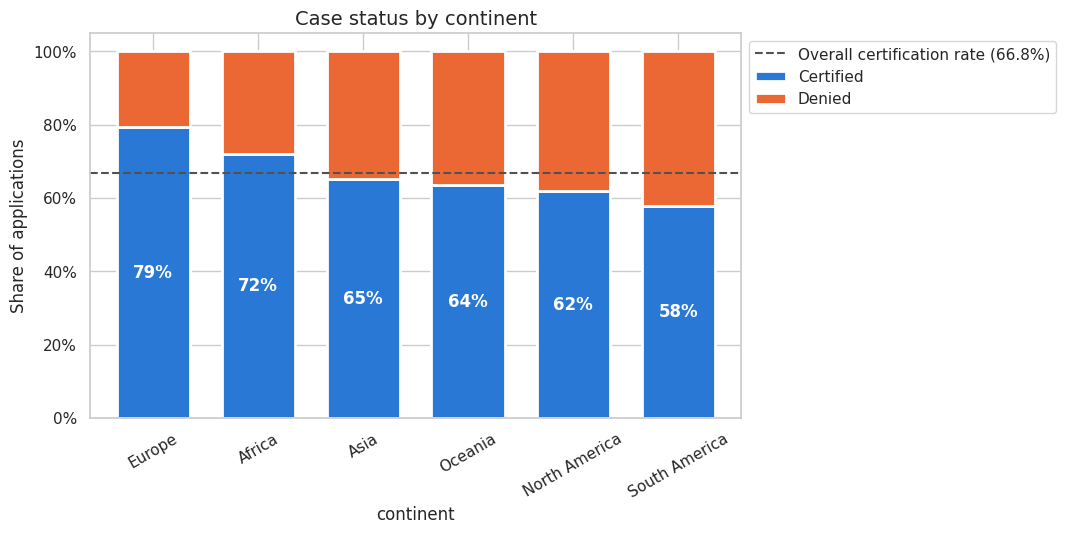

In [35]:
stacked_barplot(data, "continent")

**Observations**
* Yes. **Europe has the highest certification rate (79.2%)**, followed by Africa (72.1%).
* **South America has the lowest rate (57.9%)**, followed by North America (61.9%) and Oceania (63.5%).
* Asia, which contributes two thirds of the applications, is close to the overall rate (65.3%).
* Part of the continent effect is related to education: Europe has the largest share of Doctorate holders (22.7% of its applicants vs 5.5% in Asia), which is explored in the multivariate analysis.

### Other bivariate relationships

case_status,Certified,Denied,Total,Certification rate
requires_job_training,,,,
Y,2006,949,2955,67.9%
N,15012,7513,22525,66.6%


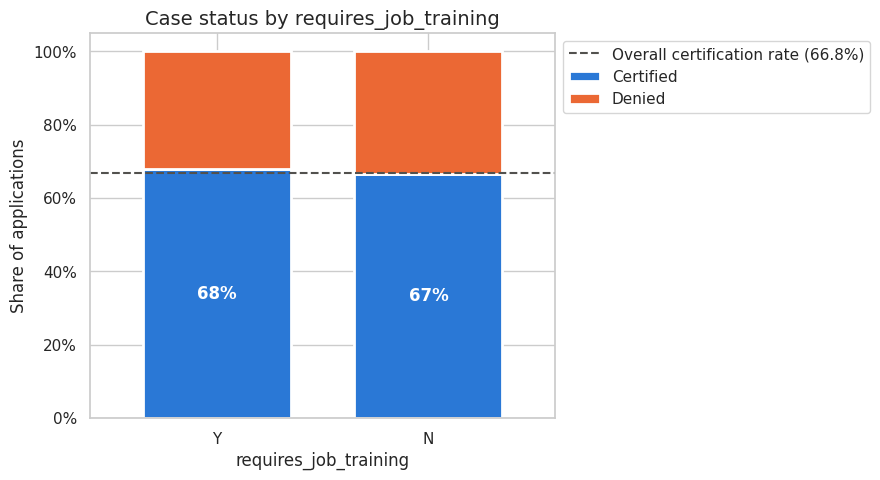

In [36]:
stacked_barplot(data, "requires_job_training")

case_status,Certified,Denied,Total,Certification rate
full_time_position,,,,
N,1855,852,2707,68.5%
Y,15163,7610,22773,66.6%


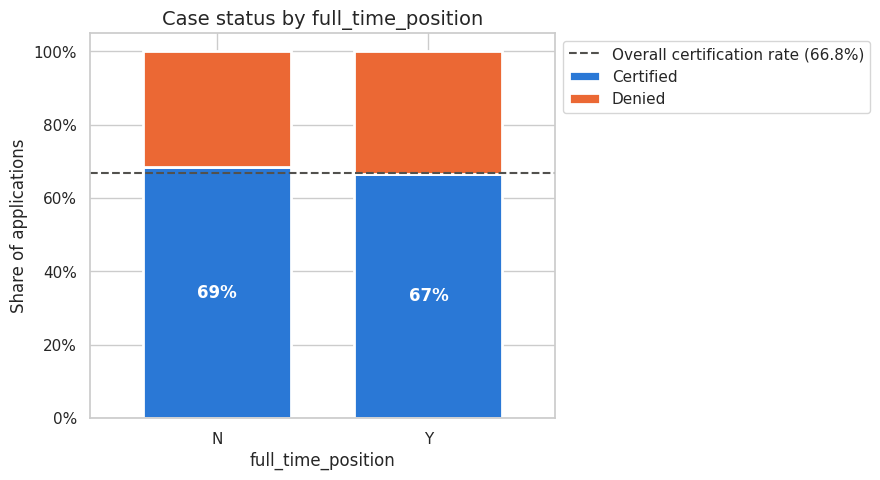

In [37]:
stacked_barplot(data, "full_time_position")

**Observations**
* **requires_job_training** and **full_time_position** barely change the certification rate: 67.9% vs 66.6% for training, and 68.5% (part-time) vs 66.6% (full-time) for the type of position. On their own, these two variables are weak predictors.

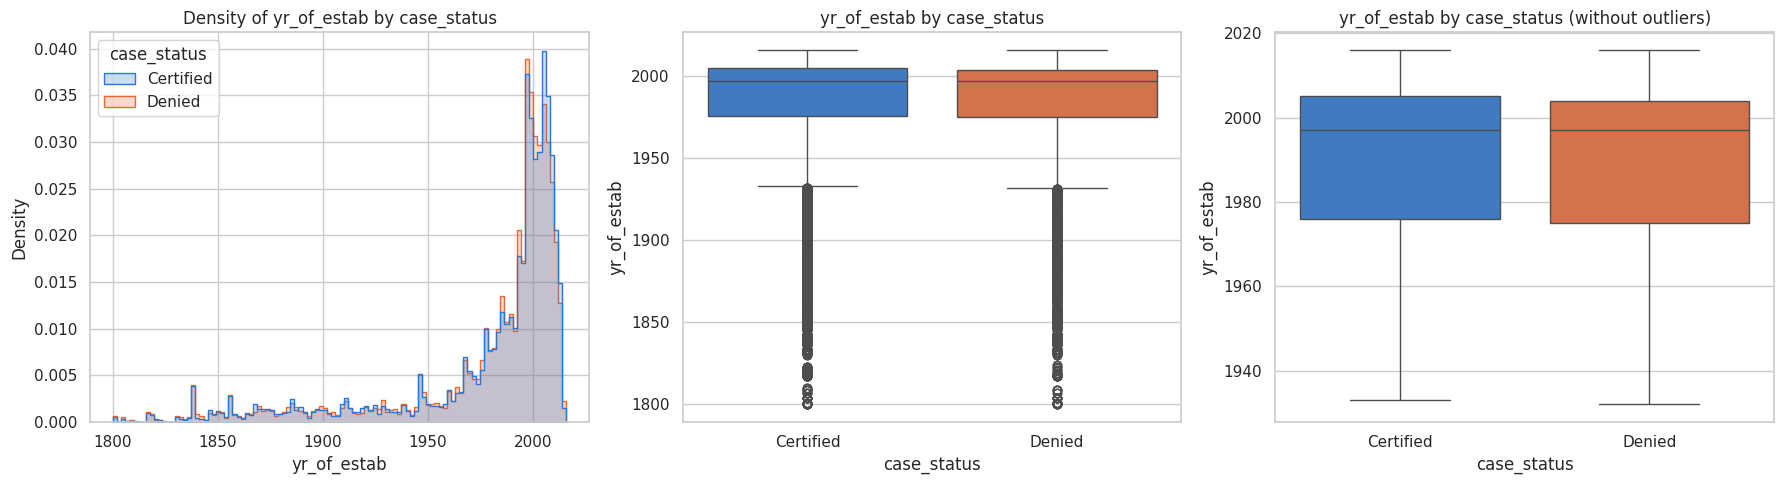

In [38]:
distribution_plot_wrt_target(data, "yr_of_estab")

case_status,Certified,Denied,Total,Certification rate
company_age,,,,
0-10 yrs,3969,1731,5700,69.6%
11-25 yrs,6468,3362,9830,65.8%
26-50 yrs,3233,1669,4902,66.0%
51-100 yrs,1565,807,2372,66.0%
>100 yrs,1783,893,2676,66.6%


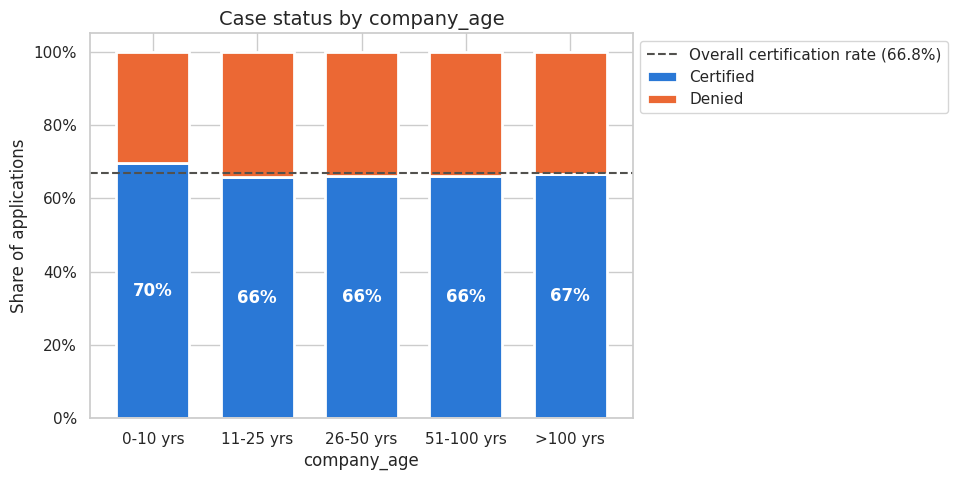

In [39]:
# Company age at the time of the applications (the data corresponds to FY 2016)
company_ages = data.assign(
    company_age=pd.cut(2016 - data["yr_of_estab"], bins=[-1, 10, 25, 50, 100, np.inf],
                       labels=["0-10 yrs", "11-25 yrs", "26-50 yrs", "51-100 yrs", ">100 yrs"])
)
stacked_barplot(company_ages, "company_age", sort_by_rate=False)

**Observations**
* The year of establishment has **very little influence** on the case status: both classes have the same median year (1997).
* Young companies (10 years old or less) have a slightly higher certification rate (69.6%) than older ones (65.8%-66.6%), but the difference is small.

## **Multivariate Analysis**

The strongest single drivers are education, job experience, unit of wage, continent, and region. The heatmaps below show how they **interact**, because the combination of characteristics defines the applicant profiles that are most likely to be certified or denied.

#### Education and job experience

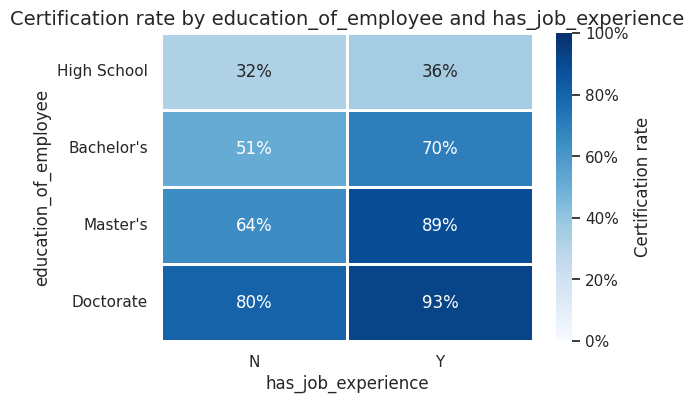

In [40]:
certification_heatmap(data, "education_of_employee", "has_job_experience", row_order=EDUCATION_ORDER)

**Observations**
* Job experience increases the certification rate at **every** education level, but the effect is much larger for higher degrees: **Master's** applicants go from 64% (no experience) to **89% (with experience)**, and Doctorates from 80% to **93%**.
* For **High School** applicants, experience barely helps (32% vs 36%): the education level dominates.
* The best profile is a **Doctorate or Master's with job experience**; the worst is a **High School applicant**, with or without experience.

#### Education and continent

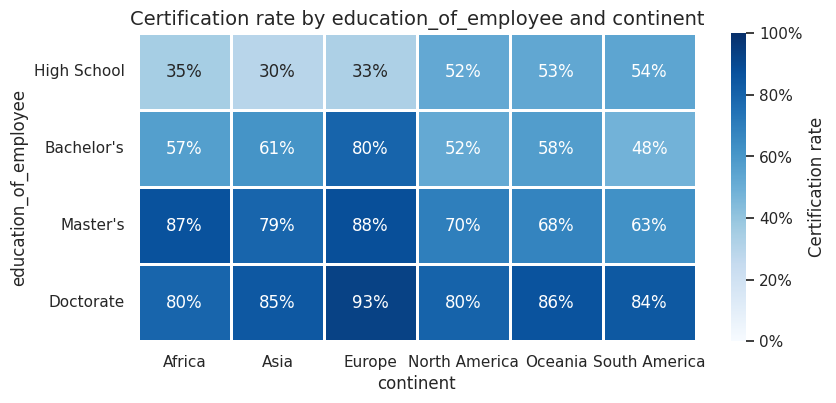

In [41]:
certification_heatmap(data, "education_of_employee", "continent", row_order=EDUCATION_ORDER)

In [42]:
# Education mix of the applicants from each continent (row percentages)
pd.crosstab(data["continent"], data["education_of_employee"], normalize="index")[EDUCATION_ORDER]

education_of_employee,High School,Bachelor's,Master's,Doctorate
continent,,,,
Africa,0.120,0.260,0.523,0.098
Asia,0.136,0.425,0.384,0.055
Europe,0.131,0.348,0.294,0.227
North America,0.122,0.372,0.428,0.078
Oceania,0.188,0.344,0.354,0.115
South America,0.161,0.391,0.344,0.104


**Observations**
* The education gradient holds on **every continent**: Doctorates are certified 80%-93% of the time everywhere.
* **Europe** combines the highest rates for Bachelor's (80%), Master's (88%), and Doctorate (93%) applicants, and it has by far the largest share of Doctorates (22.7%). This partly explains why Europe has the highest overall certification rate.
* An interesting exception: **High School** applicants from the Americas and Oceania (52%-54%) are certified much more often than High School applicants from Asia (30%) and Europe (33%).

#### Education and region of employment

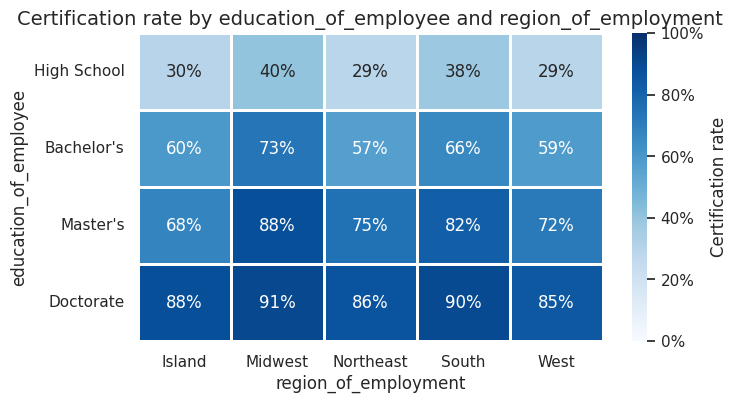

In [43]:
certification_heatmap(data, "education_of_employee", "region_of_employment", row_order=EDUCATION_ORDER)

**Observations**
* The **Midwest** has the highest certification rate for every education level (e.g., 88% for Master's and 91% for Doctorates), and the South is the second-best region.
* The Northeast and West are the least favorable regions for Bachelor's and High School applicants (57%-59% and 29%).

#### Education and unit of wage

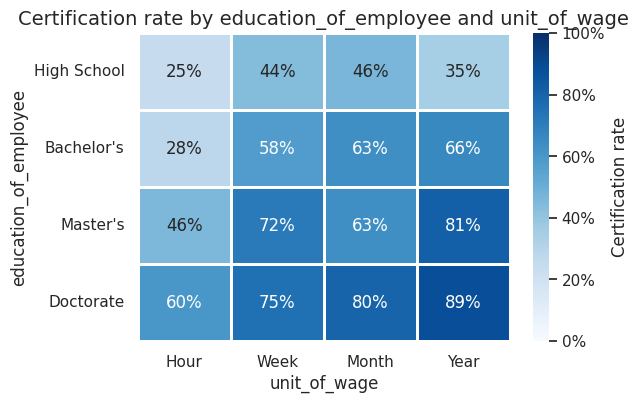

In [44]:
certification_heatmap(data, "education_of_employee", "unit_of_wage", row_order=EDUCATION_ORDER, col_order=["Hour", "Week", "Month", "Year"])

**Observations**
* Hourly-paid positions have the lowest certification rate at **every** education level: only 25% for High School and 28% for Bachelor's applicants paid hourly.
* Yearly-paid positions give the highest rates for Master's (81%) and Doctorate (89%) applicants.
* The **unit of wage is therefore an independent driver** of the case status, not just a consequence of the education of the applicant.

#### Job experience and job training

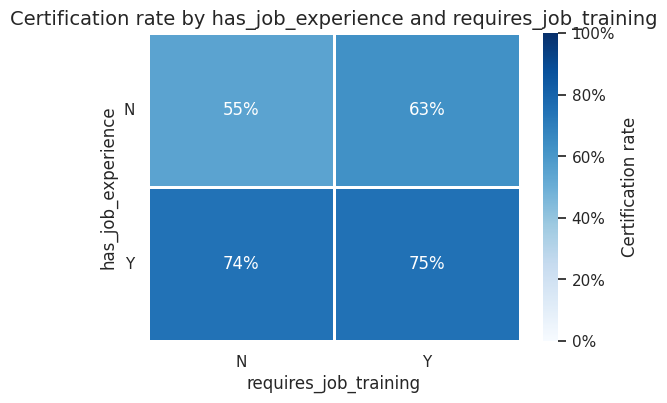

In [45]:
certification_heatmap(data, "has_job_experience", "requires_job_training")

**Observations**
* Among applicants **without** job experience, those who require training are certified more often (63%) than those who do not (55%). For experienced applicants the need for training makes no difference (75% in both cases).
* The job-training variable only adds information in combination with the lack of experience, which is a relationship that tree-based models can capture.

## **EDA Summary**

**Answers to the leading questions**

1. **Case status distribution:** 66.8% certified vs 33.2% denied, a moderate class imbalance.
2. **Education:** the strongest driver. The certification rate rises from 34.0% (High School) to 62.2% (Bachelor's), 78.6% (Master's), and 87.2% (Doctorate).
3. **Job experience:** experienced applicants are certified 74.5% of the time vs 56.1% without experience, a significant difference of ~18 percentage points.
4. **Prevailing wage:** a higher wage does **not** by itself increase the chance of approval (the certification rate is flat across the yearly wage quartiles). What matters is the **unit of wage**: hourly positions are certified only 34.6% of the time vs 69.9% for yearly salaries.
5. **Region:** the Midwest (75.5%) and South (70.0%) have the highest approval rates; the Northeast, West, and Island regions are around 60%-63%.
6. **Company size:** a weak effect; the certification rate moves between 62% and 73% across company sizes with no strong trend.
7. **Continent:** Europe has the highest approval rate (79.2%) and South America the lowest (57.9%).

**Additional insights (beyond the leading questions)**

* The numerical variables are uncorrelated with each other and have little direct relationship with the case status; the **categorical attributes of the applicant and of the job** are the main drivers.
* The effect of job experience grows with the education level (Master's: 64% → 89%), while for High School applicants experience barely matters.
* The unit of wage keeps its effect within every education level, so it is an independent driver.
* Company age, full-time status, and job training have weak individual effects.

**Implications for data preparation and modeling**

* `case_id` must be dropped, the negative `no_of_employees` values must be corrected, and all categorical variables must be encoded.
* `prevailing_wage` will be kept in its original form together with `unit_of_wage` (no unit conversion).
* The class imbalance requires a stratified split and a metric that looks beyond accuracy.

# **Data Pre-processing**

- Missing value treatment (check if needed)
- Outlier detection and treatment (check if needed)
- Feature engineering (check if needed)
- Preparing the data for modeling, including encoding, the train-test split, and scaling where needed
- Any other preprocessing steps (check if needed)

In [46]:
# Work on a copy so the data used in the EDA remains unchanged
df = data.copy()

### Missing value detection and treatment

In [47]:
# Number of missing values per column
df.isnull().sum()

,0
case_id,0
continent,0
education_of_employee,0
has_job_experience,0
requires_job_training,0
no_of_employees,0
yr_of_estab,0
region_of_employment,0
prevailing_wage,0
unit_of_wage,0


* There are **no missing values** in any column, so **no imputation or row removal is needed**.

### Treatment of invalid values

The sanity checks showed 33 rows with a negative `no_of_employees`. A company cannot have a negative number of employees, and the pattern (only the values -11, -14, -17, -25, and -26, no zeros, and a smallest positive value of 12) indicates a **sign-entry error**. Replacing them with their **absolute value** keeps these 33 applications and gives plausible company sizes (11 to 26 employees), which is better than dropping the rows.

In [48]:
# Replace the negative number of employees with its absolute value
df["no_of_employees"] = df["no_of_employees"].abs()

print("Rows with no_of_employees <= 0 after treatment:", (df["no_of_employees"] <= 0).sum())

Rows with no_of_employees <= 0 after treatment: 0


### Feature engineering

* **`company_age`**: the year of establishment is converted into the **age of the company at the time of the applications** (the data corresponds to FY 2016): `company_age = 2016 - yr_of_estab`. It carries the same information as `yr_of_estab` but is easier to interpret in the business recommendations ("companies older than X years"), so `yr_of_estab` is replaced by it.
* **`case_id`** is a unique identifier with no predictive information, so it is dropped.
* **`prevailing_wage` is not converted to a yearly wage.** As shown in the EDA, the weekly and monthly wages already have values on the same scale as yearly wages (medians ~85,000), so multiplying them by 52 or 12 would create unrealistic wages. As recommended in the FAQ, the wage is kept in its original form and `unit_of_wage` is kept as a separate feature, which captures the strong effect of hourly-paid positions found in the EDA.

In [49]:
# Age of the company in 2016 (year of the applications)
df["company_age"] = 2016 - df["yr_of_estab"]

# Drop the identifier and the original year column (replaced by company_age)
df = df.drop(columns=["case_id", "yr_of_estab"])

df["company_age"].describe()

,company_age
count,"25,480.000"
mean,36.590
std,42.367
min,0.000
25%,11.000
50%,19.000
75%,40.000
max,216.000


* `company_age` ranges from 0 (companies established in 2016) to 216 years, with a median of 19 years.

### Outlier detection and treatment

Outliers are detected with the **IQR rule**: values below Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR.

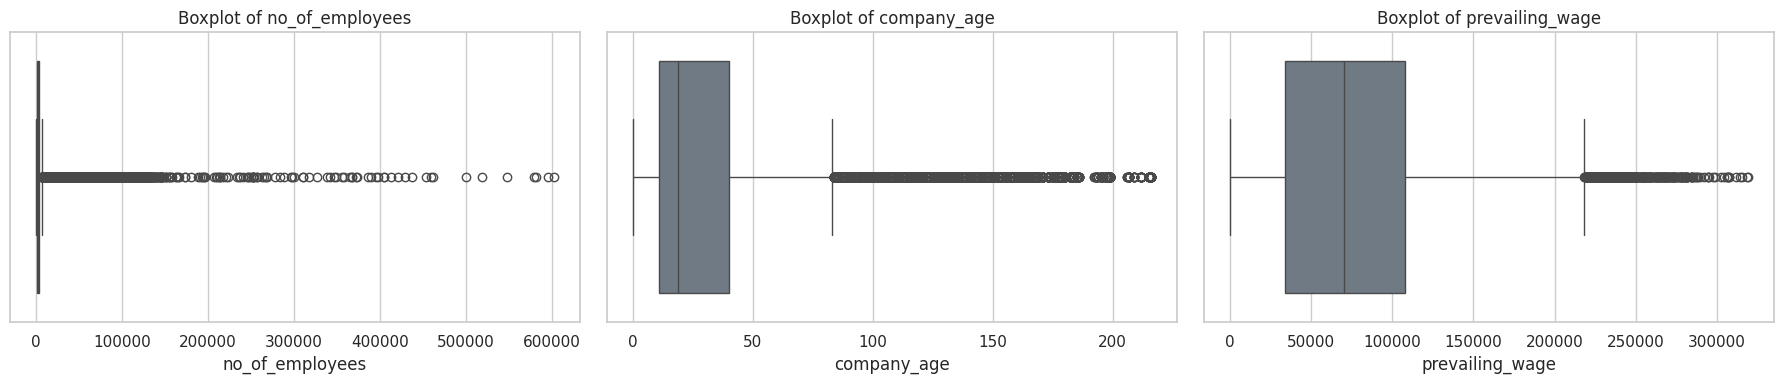

In [50]:
num_cols = ["no_of_employees", "company_age", "prevailing_wage"]

# Boxplots of the numerical features
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=df[col], ax=ax, color=NEUTRAL_COLOR)
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

In [51]:
# Number and share of outliers per column according to the IQR rule,
# and the certification rate of those outlier applications
outlier_summary = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    is_outlier = (df[col] < lower) | (df[col] > upper)
    outlier_summary.append({
        "feature": col,
        "lower_bound": lower,
        "upper_bound": upper,
        "n_outliers": is_outlier.sum(),
        "pct_outliers": 100 * is_outlier.mean(),
        "certification_rate_of_outliers": 100 * df.loc[is_outlier, "case_status"].eq("Certified").mean(),
    })

pd.DataFrame(outlier_summary).set_index("feature")

,lower_bound,upper_bound,n_outliers,pct_outliers,certification_rate_of_outliers
feature,,,,,
no_of_employees,"-2,701.000","7,227.000",1556,6.107,68.252
company_age,-32.500,83.500,3260,12.794,66.656
prevailing_wage,"-76,564.569","218,315.561",427,1.676,77.049


**Observations and decision**

* `no_of_employees` has 1,556 outliers (6.1%), all above ~7,227 employees; `company_age` has 3,260 outliers (12.8%), companies older than ~83 years; `prevailing_wage` has 427 outliers (1.7%), wages above ~218,316.
* These values are **not errors**: large multinational employers, companies founded more than 80 years ago, and high-paying specialized positions are all realistic. They also carry information: for example, the applications with very high wages have a certification rate of 77%, higher than the average of 66.8%.
* **Decision: the outliers are not removed or capped.** Removing them would discard 4,950 applications (19.4% of the data, counting each row once) and genuine information, and capping would distort the real values.
    * The **Decision Tree and Random Forest** split on thresholds, so they are not affected by extreme values.
    * For the **Logistic Regression**, the numerical features will be standardized. A log transformation of the skewed `no_of_employees` was also considered, but it did not change the Logistic Regression performance in a test run, so it is not applied to keep the features interpretable.

### Preparing the data for modeling

#### Encoding the target and the categorical features

* **Target:** `case_status` is encoded as **Certified = 1** and **Denied = 0**, so the models predict the probability that a visa is certified (the class that OFLC wants to shortlist).
* **Binary Y/N features** (`has_job_experience`, `requires_job_training`, `full_time_position`) are encoded as **1 = Y** and **0 = N**.
* **Multi-category features** (`continent`, `education_of_employee`, `region_of_employment`, `unit_of_wage`) are **one-hot encoded**. One-hot encoding does not impose an artificial order or equal spacing between categories. `drop_first=True` removes one redundant dummy per feature (it can be inferred from the others), which avoids perfect multicollinearity in the Logistic Regression.

In [52]:
# Target: 1 = Certified, 0 = Denied
df["case_status"] = df["case_status"].map({"Certified": 1, "Denied": 0})

# Binary Y/N features: 1 = Y, 0 = N
binary_cols = ["has_job_experience", "requires_job_training", "full_time_position"]
for col in binary_cols:
    df[col] = df[col].map({"Y": 1, "N": 0})

df[["case_status"] + binary_cols].head()

,case_status,has_job_experience,requires_job_training,full_time_position
0,0,0,0,1
1,1,1,0,1
2,0,0,1,1
3,0,0,0,1
4,1,1,0,1


In [53]:
# Separate the independent variables (X) and the target (y)
X = df.drop(columns=["case_status"])
y = df["case_status"]

# One-hot encoding of the multi-category features (the first category of each one is dropped)
X = pd.get_dummies(
    X,
    columns=["continent", "education_of_employee", "region_of_employment", "unit_of_wage"],
    drop_first=True,
    dtype=int,
)

print("Shape of X after encoding:", X.shape)
X.head()

Shape of X after encoding: (25480, 21)


,has_job_experience,requires_job_training,no_of_employees,prevailing_wage,full_time_position,company_age,continent_Asia,continent_Europe,continent_North America,continent_Oceania,continent_South America,education_of_employee_Doctorate,education_of_employee_High School,education_of_employee_Master's,region_of_employment_Midwest,region_of_employment_Northeast,region_of_employment_South,region_of_employment_West,unit_of_wage_Month,unit_of_wage_Week,unit_of_wage_Year
0,0,0,14513,592.203,1,9,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0
1,1,0,2412,"83,425.650",1,14,1,0,0,0,0,0,0,1,0,1,0,0,0,0,1
2,0,1,44444,"122,996.860",1,8,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,0,0,98,"83,434.030",1,119,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
4,1,0,1082,"149,907.390",1,11,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1


* After encoding, there are **21 features**. The dropped reference categories are: `continent = Africa`, `education_of_employee = Bachelor's`, `region_of_employment = Island`, and `unit_of_wage = Hour`.

#### Train-test split

The data is split into **70% training** and **30% test** sets. The split is **stratified** on the target so that both sets keep the same proportion of certified and denied cases (~67% / 33%), which gives a fair evaluation given the class imbalance.

In [54]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

print("Training set shape:", X_train.shape)
print("Test set shape:    ", X_test.shape)
print()
print("Share of each class in the training set:")
print(y_train.value_counts(normalize=True).rename({1: "Certified (1)", 0: "Denied (0)"}))
print()
print("Share of each class in the test set:")
print(y_test.value_counts(normalize=True).rename({1: "Certified (1)", 0: "Denied (0)"}))

Training set shape: (17836, 21)
Test set shape:     (7644, 21)

Share of each class in the training set:
case_status
Certified (1)   0.668
Denied (0)      0.332
Name: proportion, dtype: float64

Share of each class in the test set:
case_status
Certified (1)   0.668
Denied (0)      0.332
Name: proportion, dtype: float64


#### Scaling

* **Logistic Regression** is sensitive to the scale of the features (and its regularization penalizes all coefficients equally), so the numerical features `no_of_employees`, `company_age`, and `prevailing_wage`, which have very different ranges, are standardized with `StandardScaler` (mean 0, standard deviation 1). The 0/1 encoded features are left as they are so they stay interpretable.
* The scaler is **fitted on the training set only** and then applied to the test set, so no information from the test set leaks into the training process.
* **Decision Tree and Random Forest** split on threshold values rather than distances, so they are trained on the **encoded, unscaled** data (`X_train`, `X_test`).

In [55]:
# Fit the scaler on the training data only, then transform both sets
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

# Check: the scaled training features have mean ~0 and standard deviation ~1
X_train_scaled[num_cols].describe().loc[["mean", "std"]]

,no_of_employees,company_age,prevailing_wage
mean,-0.000,-0.000,0.000
std,1.000,1.000,1.000


### Summary of the data pre-processing

| Step | Needed? | Action taken |
|---|---|---|
| Missing values | No | No missing values were found; no treatment applied. |
| Invalid values | Yes | 33 negative `no_of_employees` replaced by their absolute value. |
| Outliers | Detected, not treated | Genuine values (large companies, old companies, high wages); tree models are robust and the Logistic Regression uses scaled features. |
| Feature engineering | Yes | `company_age` created from `yr_of_estab`; `case_id` dropped; `prevailing_wage` kept without unit conversion (see FAQ and EDA). |
| Encoding | Yes | Target and Y/N features mapped to 1/0; multi-category features one-hot encoded (21 features). |
| Train-test split | Yes | 70/30 stratified split. |
| Scaling | Only for Logistic Regression | `StandardScaler` fitted on the training set and applied to the numerical features. |

# **Model Building: Logistic Regression, Decision Tree, and Random Forest**

- Define the model evaluation criterion for this business problem by identifying the cost of a false positive and a false negative, and choose an appropriate primary metric.
- Build a Logistic Regression model on the scaled data.
- Build a Decision Tree model on the encoded data.
- Build a Random Forest model on the encoded data.
- Evaluate each model on the training data and the test data, and comment on overfitting or the generalization gap.

### Model evaluation criterion

The models predict the class **Certified (1)** vs **Denied (0)**. They can make two kinds of wrong predictions:

* **False Positive (FP):** the model predicts **Certified**, but the application should be **Denied**. OFLC could shortlist and approve a candidate who does not meet the requirements, which means a foreign worker may take a job that should go to a US worker, undermining the purpose of the INA to protect US workers' wages and working conditions, and exposing OFLC to compliance risk.
* **False Negative (FN):** the model predicts **Denied**, but the application should be **Certified**. A qualified applicant is deprioritized or rejected: the US employer loses the talent it needs to cover a workforce shortage, the applicant loses a legitimate opportunity, and the case needs additional manual review.

**Both errors are costly** for OFLC and EasyVisa: a false positive hurts US workers and the integrity of the program, while a false negative hurts US companies and qualified applicants. Therefore, the metric must balance both types of error:

* **Recall** (of the certified class) measures how many of the applications that should be certified are identified, so it penalizes false negatives.
* **Precision** measures how many of the applications predicted as certified really deserve it, so it penalizes false positives.
* Accuracy is not a good choice because of the class imbalance (a model that always predicts "Certified" reaches ~67% accuracy).

**Primary metric: F1-score**, the harmonic mean of precision and recall. It is high only when both false positives and false negatives are low. Accuracy, precision, and recall are also reported for every model.

#### Functions to evaluate the models

The two functions below compute the performance metrics and plot the confusion matrix, so that all models are evaluated in exactly the same way on the training and test sets.

In [56]:
def model_performance(model, predictors, target):
    """Return the Accuracy, Recall, Precision, and F1-score of a fitted classifier as a one-row DataFrame."""
    pred = model.predict(predictors)
    return pd.DataFrame(
        {
            "Accuracy": [accuracy_score(target, pred)],
            "Recall": [recall_score(target, pred)],
            "Precision": [precision_score(target, pred)],
            "F1": [f1_score(target, pred)],
        }
    )


def train_test_performance(model, X_tr, y_tr, X_te, y_te):
    """Metrics of a fitted model on the training and test sets, plus the generalization gap (train - test)."""
    perf = pd.concat([model_performance(model, X_tr, y_tr), model_performance(model, X_te, y_te)])
    perf.index = ["Train", "Test"]
    perf.loc["Gap (Train - Test)"] = perf.loc["Train"] - perf.loc["Test"]
    return perf


def plot_confusion_matrices(model, X_tr, y_tr, X_te, y_te, title):
    """Side-by-side confusion matrices (count and percentage of all cases) for the training and test sets."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, X_, y_, name in zip(axes, [X_tr, X_te], [y_tr, y_te], ["Training set", "Test set"]):
        # labels=[1, 0] puts "Certified" (positive class) in the first row and column
        cm = confusion_matrix(y_, model.predict(X_), labels=[1, 0])
        annot = np.array([[f"{v:,}\n{v / cm.sum():.1%}" for v in row] for row in cm])
        sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
                    xticklabels=STATUS_ORDER, yticklabels=STATUS_ORDER, ax=ax)
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("True label")
        ax.set_title(name)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

### Logistic Regression (on the scaled data)

The `newton-cg` solver is used; it fits the same L2-regularized model as the default solver and converges reliably on this data.

In [57]:
log_reg = LogisticRegression(solver="newton-cg", max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

log_reg_perf = train_test_performance(log_reg, X_train_scaled, y_train, X_test_scaled, y_test)
log_reg_perf

,Accuracy,Recall,Precision,F1
Train,0.741,0.881,0.766,0.819
Test,0.731,0.875,0.759,0.813
Gap (Train - Test),0.009,0.006,0.007,0.006


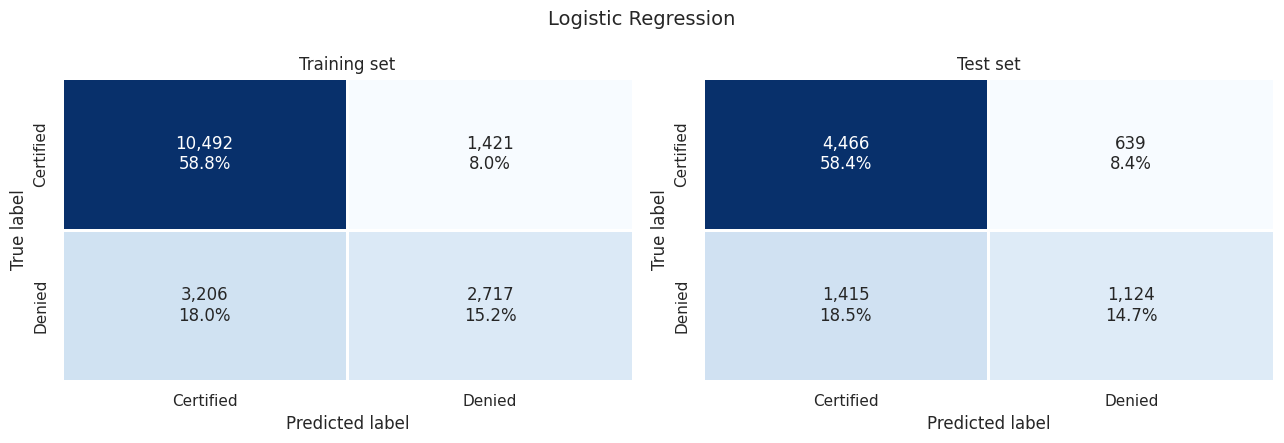

In [58]:
plot_confusion_matrices(log_reg, X_train_scaled, y_train, X_test_scaled, y_test, "Logistic Regression")

**Observations**
* The Logistic Regression reaches an **F1-score of 0.819 on the training set and 0.813 on the test set**; the generalization gap is below one percentage point in every metric, so the model **does not overfit**.
* It has a high recall (~0.88): it identifies almost 9 out of 10 applications that deserve certification. Its precision (~0.76) is lower: about one in four applications predicted as certified is actually denied.
* The confusion matrix shows that most errors are **false positives** (denied applications predicted as certified), so the model struggles most to recognize denied cases.

### Decision Tree (on the encoded data)

In [59]:
dtree = DecisionTreeClassifier(random_state=RANDOM_STATE)
dtree.fit(X_train, y_train)

print(f"Depth of the tree: {dtree.get_depth()} | Number of leaves: {dtree.get_n_leaves():,}")
dtree_perf = train_test_performance(dtree, X_train, y_train, X_test, y_test)
dtree_perf

Depth of the tree: 42 | Number of leaves: 4,159


,Accuracy,Recall,Precision,F1
Train,1.000,1.000,1.000,1.000
Test,0.653,0.741,0.740,0.740
Gap (Train - Test),0.347,0.259,0.260,0.260


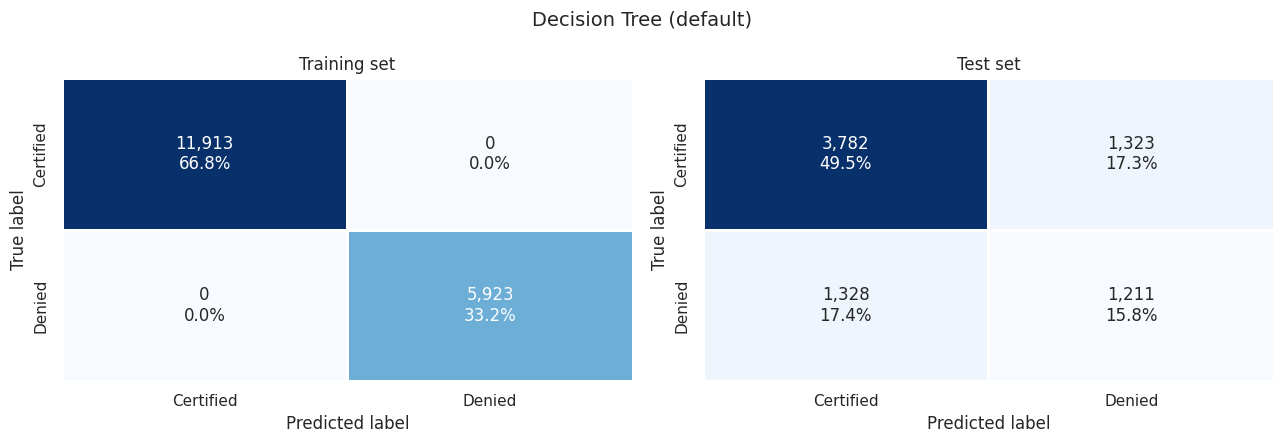

In [60]:
plot_confusion_matrices(dtree, X_train, y_train, X_test, y_test, "Decision Tree (default)")

**Observations**
* The default Decision Tree grows without any limit (depth 42 and more than 4,000 leaves), so it **memorizes the training data**: it classifies 100% of the training applications correctly.
* On the test set, its F1-score drops to **0.740** (accuracy 0.653), a **generalization gap of 0.26 in F1**. This is **severe overfitting**: the tree learned noise from individual applications instead of general patterns, and it performs worse than the Logistic Regression on new data.

#### Decision Tree with limited complexity (pre-pruning)

To reduce overfitting, the complexity of the tree is limited with `max_depth` (maximum number of levels) and `min_samples_leaf` (minimum number of applications in each final leaf). The best combination is selected with **5-fold stratified cross-validation on the training set**, using the F1-score. The test set is not used for this choice.

In [61]:
# Cross-validation folds shared by the tuned models (stratified to keep the class ratio in every fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

dtree_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid={
        "max_depth": [3, 4, 5, 6, 8, 10],
        "min_samples_leaf": [1, 10, 25, 50],
    },
    scoring="f1",
    cv=cv,
    n_jobs=-1,
)
dtree_grid.fit(X_train, y_train)

print("Best parameters:", dtree_grid.best_params_)
print(f"Cross-validated F1-score: {dtree_grid.best_score_:.3f}")

dtree_tuned = dtree_grid.best_estimator_
dtree_tuned_perf = train_test_performance(dtree_tuned, X_train, y_train, X_test, y_test)
dtree_tuned_perf

Best parameters: {'max_depth': 5, 'min_samples_leaf': 50}
Cross-validated F1-score: 0.822


,Accuracy,Recall,Precision,F1
Train,0.737,0.916,0.747,0.823
Test,0.731,0.914,0.742,0.819
Gap (Train - Test),0.006,0.002,0.005,0.004


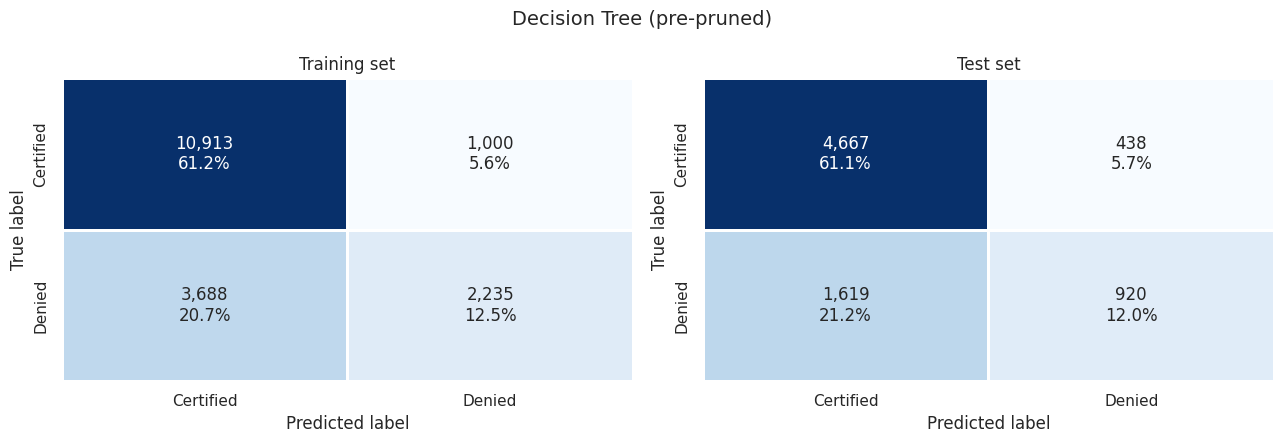

In [62]:
plot_confusion_matrices(dtree_tuned, X_train, y_train, X_test, y_test, "Decision Tree (pre-pruned)")

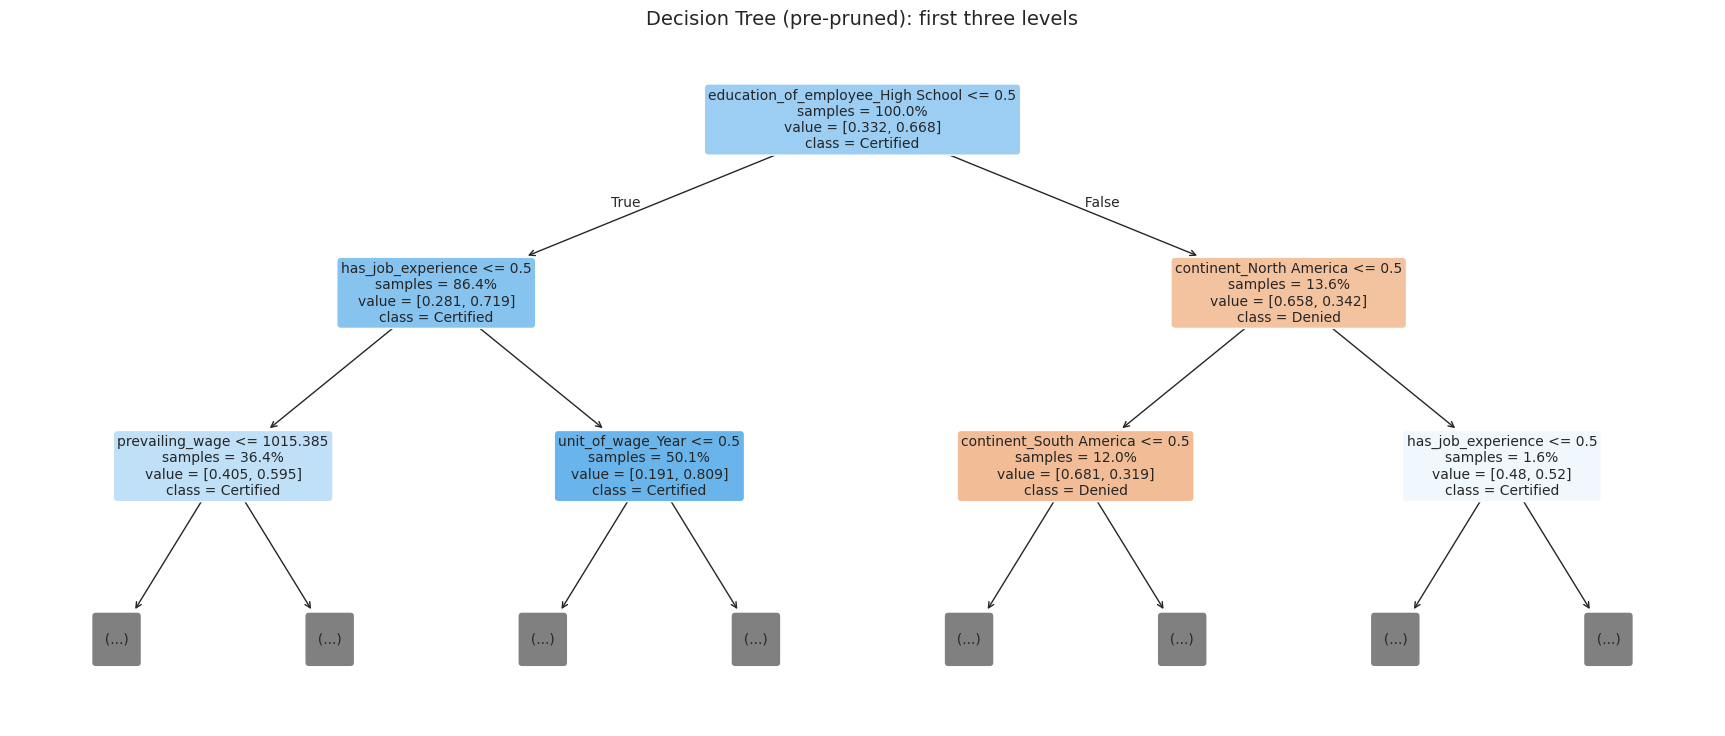

In [63]:
# Top levels of the pruned tree (the full tree has 5 levels)
plt.figure(figsize=(22, 9))
plot_tree(dtree_tuned, max_depth=2, feature_names=X_train.columns.tolist(), class_names=["Denied", "Certified"],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=10)
plt.title("Decision Tree (pre-pruned): first three levels", fontsize=14)
plt.show()

**Observations**
* Limiting the tree to **5 levels with at least 50 applications per leaf** removes the overfitting: the F1-score is **0.823 on training and 0.819 on test** (gap of 0.004).
* Compared with the default tree, the test F1-score improves from 0.740 to 0.819, and it is now slightly better than the Logistic Regression. The pruned tree has a very high recall (~0.91) but a lower precision (~0.74).
* The tree confirms the drivers found in the EDA:
    * The **first split is on education (High School vs higher degrees)**. High School applicants are mostly predicted as denied (only 34% certified in that node).
    * For applicants with a higher degree, the next split is **job experience**, and then the **unit of wage (yearly)** for experienced applicants and **prevailing_wage <= ~1,015** (the range of hourly wages) for applicants without experience. Experienced applicants with a higher degree reach an 81% certification rate at the third level.
    * For High School applicants, the tree separates those from **North America** (and then South America), consistent with the higher approval rate of High School applicants from the Americas seen in the multivariate analysis.

### Random Forest (on the encoded data)

In [64]:
rf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)

rf_perf = train_test_performance(rf, X_train, y_train, X_test, y_test)
rf_perf

,Accuracy,Recall,Precision,F1
Train,1.000,1.000,1.000,1.000
Test,0.720,0.833,0.767,0.799
Gap (Train - Test),0.280,0.167,0.233,0.201


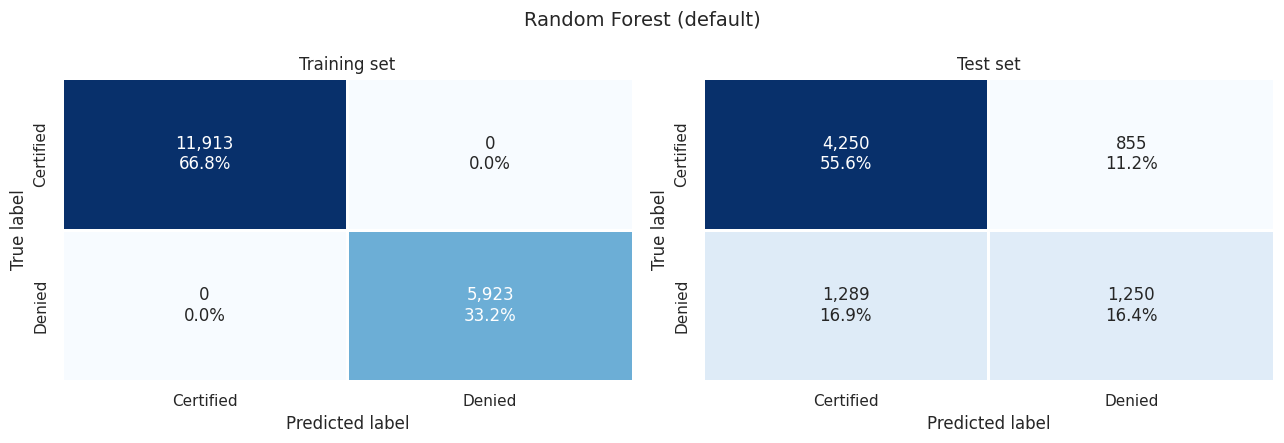

In [65]:
plot_confusion_matrices(rf, X_train, y_train, X_test, y_test, "Random Forest (default)")

**Observations**
* The default Random Forest also **fits the training data perfectly** (F1 = 1.000), because each of its 100 trees is grown to full depth.
* On the test set, the F1-score is **0.799**: much better than the single default tree (0.740), since averaging many trees reduces variance, but the **gap of ~0.20 still indicates clear overfitting**, and it is below the Logistic Regression.

#### Random Forest with limited complexity (tuned)

As with the Decision Tree, the depth of the trees and the minimum leaf size are limited, and the best combination is selected by 5-fold stratified cross-validation on the training set using the F1-score. The forest uses 200 trees, and each split considers a random subset of features (`max_features="sqrt"`), which makes the trees more diverse.

In [66]:
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(n_estimators=200, max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={
        "max_depth": [8, 10, 12],
        "min_samples_leaf": [5, 10],
    },
    scoring="f1",
    cv=cv,
    n_jobs=-1,
)
rf_grid.fit(X_train, y_train)

print("Best parameters:", rf_grid.best_params_)
print(f"Cross-validated F1-score: {rf_grid.best_score_:.3f}")

rf_tuned = rf_grid.best_estimator_
rf_tuned_perf = train_test_performance(rf_tuned, X_train, y_train, X_test, y_test)
rf_tuned_perf

Best parameters: {'max_depth': 10, 'min_samples_leaf': 10}
Cross-validated F1-score: 0.827


,Accuracy,Recall,Precision,F1
Train,0.762,0.890,0.783,0.833
Test,0.744,0.881,0.769,0.821
Gap (Train - Test),0.018,0.009,0.014,0.012


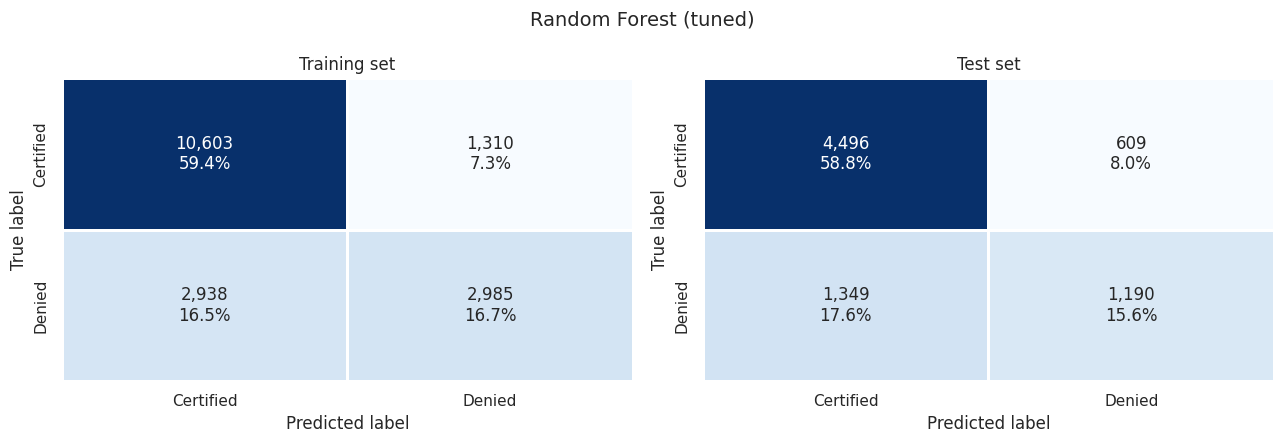

In [67]:
plot_confusion_matrices(rf_tuned, X_train, y_train, X_test, y_test, "Random Forest (tuned)")

**Observations**
* With trees limited to **depth 10 and at least 10 applications per leaf**, the Random Forest reaches an **F1-score of 0.833 on training and 0.821 on test**. The gap drops from ~0.20 to about 0.01, so the overfitting is **controlled**.
* The tuned Random Forest has the **highest test F1-score** of all the models built, with a good balance between recall (~0.88) and precision (~0.77).

# **Model Performance Comparison and Final Model Selection**

- Compare the training and test performance of all three models on your chosen primary metric, along with Accuracy, Precision, and Recall.
- Identify which model overfits the most and which model generalizes best.
- Select a final model with a clear, metric-based justification tied to the business problem.
- Report the final model's performance on the test data.

### Training and test performance of all the models

In [68]:
# Performance tables of all the models built in the previous section
all_models_perf = {
    "Logistic Regression": log_reg_perf,
    "Decision Tree (default)": dtree_perf,
    "Decision Tree (pre-pruned)": dtree_tuned_perf,
    "Random Forest (default)": rf_perf,
    "Random Forest (tuned)": rf_tuned_perf,
}

# One column per model, one row per metric and data set
comparison = pd.concat(
    {name: perf.loc[["Train", "Test"]].stack() for name, perf in all_models_perf.items()}, axis=1
)
comparison.index = [f"{metric} ({split})" for split, metric in comparison.index]
comparison = comparison.sort_index(key=lambda idx: idx.str.contains("Test"))
comparison

,Logistic Regression,Decision Tree (default),Decision Tree (pre-pruned),Random Forest (default),Random Forest (tuned)
Accuracy (Train),0.741,1.000,0.737,1.000,0.762
Recall (Train),0.881,1.000,0.916,1.000,0.890
Precision (Train),0.766,1.000,0.747,1.000,0.783
F1 (Train),0.819,1.000,0.823,1.000,0.833
Accuracy (Test),0.731,0.653,0.731,0.720,0.744
Recall (Test),0.875,0.741,0.914,0.833,0.881
Precision (Test),0.759,0.740,0.742,0.767,0.769
F1 (Test),0.813,0.740,0.819,0.799,0.821


In [69]:
# Train F1, test F1, and generalization gap of each model (primary metric)
f1_summary = pd.DataFrame(
    {
        "F1 (Train)": {name: perf.loc["Train", "F1"] for name, perf in all_models_perf.items()},
        "F1 (Test)": {name: perf.loc["Test", "F1"] for name, perf in all_models_perf.items()},
    }
)
f1_summary["Gap (Train - Test)"] = f1_summary["F1 (Train)"] - f1_summary["F1 (Test)"]
f1_summary.sort_values("F1 (Test)", ascending=False)

,F1 (Train),F1 (Test),Gap (Train - Test)
Random Forest (tuned),0.833,0.821,0.012
Decision Tree (pre-pruned),0.823,0.819,0.004
Logistic Regression,0.819,0.813,0.006
Random Forest (default),1.000,0.799,0.201
Decision Tree (default),1.000,0.740,0.260


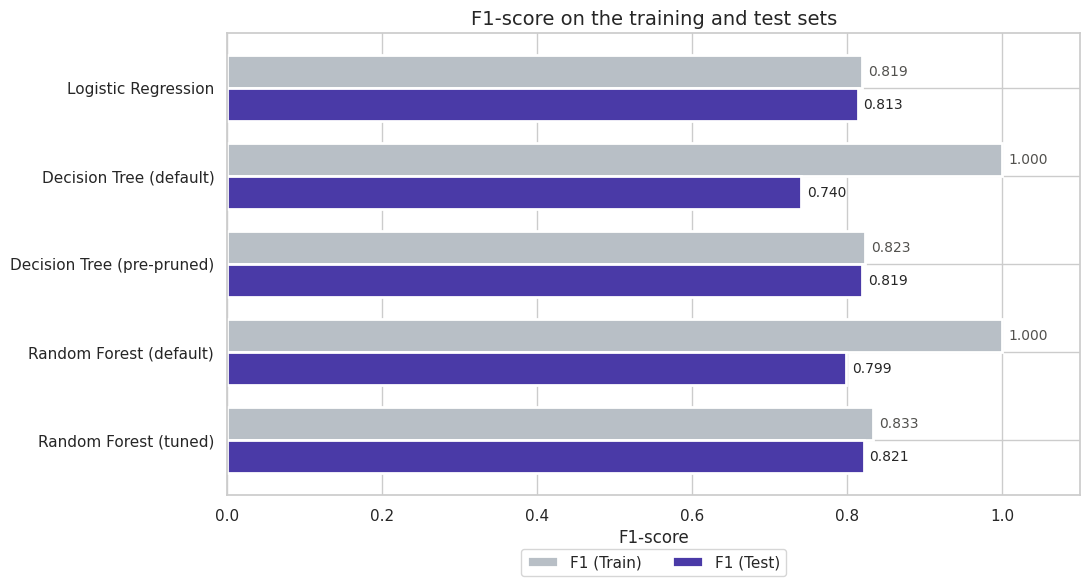

In [70]:
# Grouped bar chart of the F1-score on the training and test sets
ax = f1_summary[["F1 (Train)", "F1 (Test)"]].plot(
    kind="barh", figsize=(11, 6), color=["#b8bfc6", "#4a3aa7"], edgecolor="white", linewidth=2, width=0.75
)
ax.bar_label(ax.containers[1], fmt="%.3f", padding=4, fontsize=10)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=4, fontsize=10, color="#52514e")
ax.set_xlim(0, 1.1)
ax.set_xlabel("F1-score")
ax.set_title("F1-score on the training and test sets", fontsize=14)
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.show()

**Observations: overfitting and generalization**

* **The default Decision Tree overfits the most.** It is perfect on the training set (F1 = 1.000) but reaches only 0.740 on the test set, a gap of **0.260**, and it has the lowest test performance on every metric (accuracy of only 0.653).
* The **default Random Forest** also overfits strongly (gap of 0.201). Averaging 100 trees makes it better than the single tree on the test set (0.799), but it is still worse than the simpler models.
* **The pre-pruned Decision Tree generalizes best** (smallest gap: 0.004), followed by the Logistic Regression (0.006) and the tuned Random Forest (0.012). All three have a gap of about one percentage point or less, so their training performance is a reliable estimate of their performance on new applications.
* Limiting the complexity of the trees (depth and minimum leaf size) was the key step: it turned the two most overfitted models into the two best models on the test set.

### Final model selection

The three models that generalize well have similar F1-scores, so the choice also looks at how each one balances the two types of error on the test set (7,644 applications: 5,105 certified and 2,539 denied):

| Model | F1 (Test) | Recall | Precision | False positives | False negatives | Denied cases correctly flagged |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.813 | 0.875 | 0.759 | 1,415 | 639 | 1,124 (44.3%) |
| Decision Tree (pre-pruned) | 0.819 | 0.914 | 0.742 | 1,619 | 438 | 920 (36.2%) |
| **Random Forest (tuned)** | **0.821** | 0.881 | **0.769** | **1,349** | 609 | **1,190 (46.9%)** |

**The tuned Random Forest is selected as the final model** because:

1. It has the **highest F1-score on the test set (0.821)**, the primary metric, and also the highest cross-validated F1-score on the training set (0.827), so its advantage is consistent and not the result of a lucky split.
2. It has the **highest precision (0.769) and accuracy (0.744)** while keeping a high recall (0.881). It produces the **fewest false positives** (1,349), which means fewer unqualified applications shortlisted for certification and better protection for US workers.
3. The pruned Decision Tree has a higher recall, but it achieves it by predicting "Certified" much more often: it flags only 36% of the denied cases and produces 270 more false positives than the Random Forest. The Random Forest gives the **best balance between both costly errors**, which is exactly what the F1 criterion asks for.
4. Its generalization gap is small (0.012), so its performance on new applications should be close to what was measured.

### Final model: Random Forest (tuned)

In [71]:
final_model = rf_tuned

print("Final model:", final_model)
print()
final_test_perf = model_performance(final_model, X_test, y_test)
final_test_perf.index = ["Random Forest (tuned) - Test"]
final_test_perf

Final model: RandomForestClassifier(max_depth=10, min_samples_leaf=10, n_estimators=200,
                       n_jobs=-1, random_state=42)



,Accuracy,Recall,Precision,F1
Random Forest (tuned) - Test,0.744,0.881,0.769,0.821


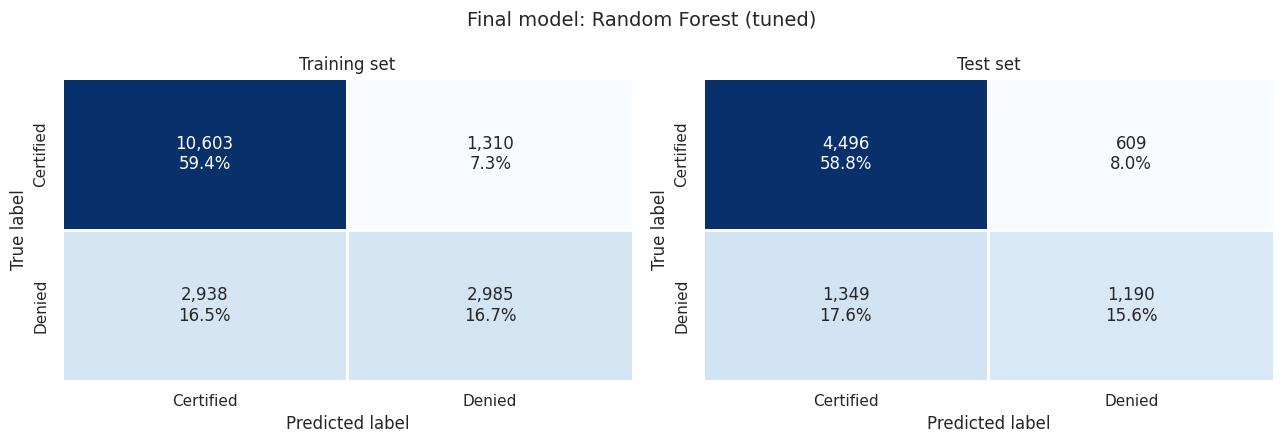

In [72]:
plot_confusion_matrices(final_model, X_train, y_train, X_test, y_test, "Final model: Random Forest (tuned)")

In [73]:
# Translate the test-set confusion matrix into business terms
tp, fn, fp, tn = confusion_matrix(y_test, final_model.predict(X_test), labels=[1, 0]).ravel()

print(f"Test applications:                          {len(y_test):,}")
print(f"Certified cases correctly shortlisted (TP):  {tp:,} of {tp + fn:,} ({tp / (tp + fn):.1%})")
print(f"Denied cases correctly flagged (TN):         {tn:,} of {tn + fp:,} ({tn / (tn + fp):.1%})")
print(f"Denied cases predicted as certified (FP):    {fp:,}")
print(f"Certified cases predicted as denied (FN):    {fn:,}")

Test applications:                          7,644
Certified cases correctly shortlisted (TP):  4,496 of 5,105 (88.1%)
Denied cases correctly flagged (TN):         1,190 of 2,539 (46.9%)
Denied cases predicted as certified (FP):    1,349
Certified cases predicted as denied (FN):    609


**Final model performance on the test data**

* On the 7,644 unseen test applications, the tuned Random Forest achieves **F1 = 0.821, recall = 0.881, precision = 0.769, and accuracy = 0.744**, very close to its training performance (F1 = 0.833).
* It **correctly shortlists 88.1% of the applications that deserve certification** (4,496 of 5,105), and **77% of the applications it predicts as certified are actually certified**.
* Its main limitation is recognizing denied cases: it flags 46.9% of them (1,190 of 2,539), which is the best among the models built but still means that 1,349 denied applications are predicted as certified. For this reason, the model should be used to **prioritize and support** the review of the applications, not to replace the final decision of the OFLC officers (see the recommendations below).

# **Actionable Insights and Recommendations**

### Key drivers according to the final model

Two importance measures are compared for the tuned Random Forest:
* **Impurity-based importance** (built into the Random Forest): how much each feature reduces the impurity of the splits. It tends to favor continuous features with many possible split points.
* **Permutation importance on the test set**: how much the test F1-score drops when the values of a feature are randomly shuffled. It measures what the model really relies on to predict unseen applications.

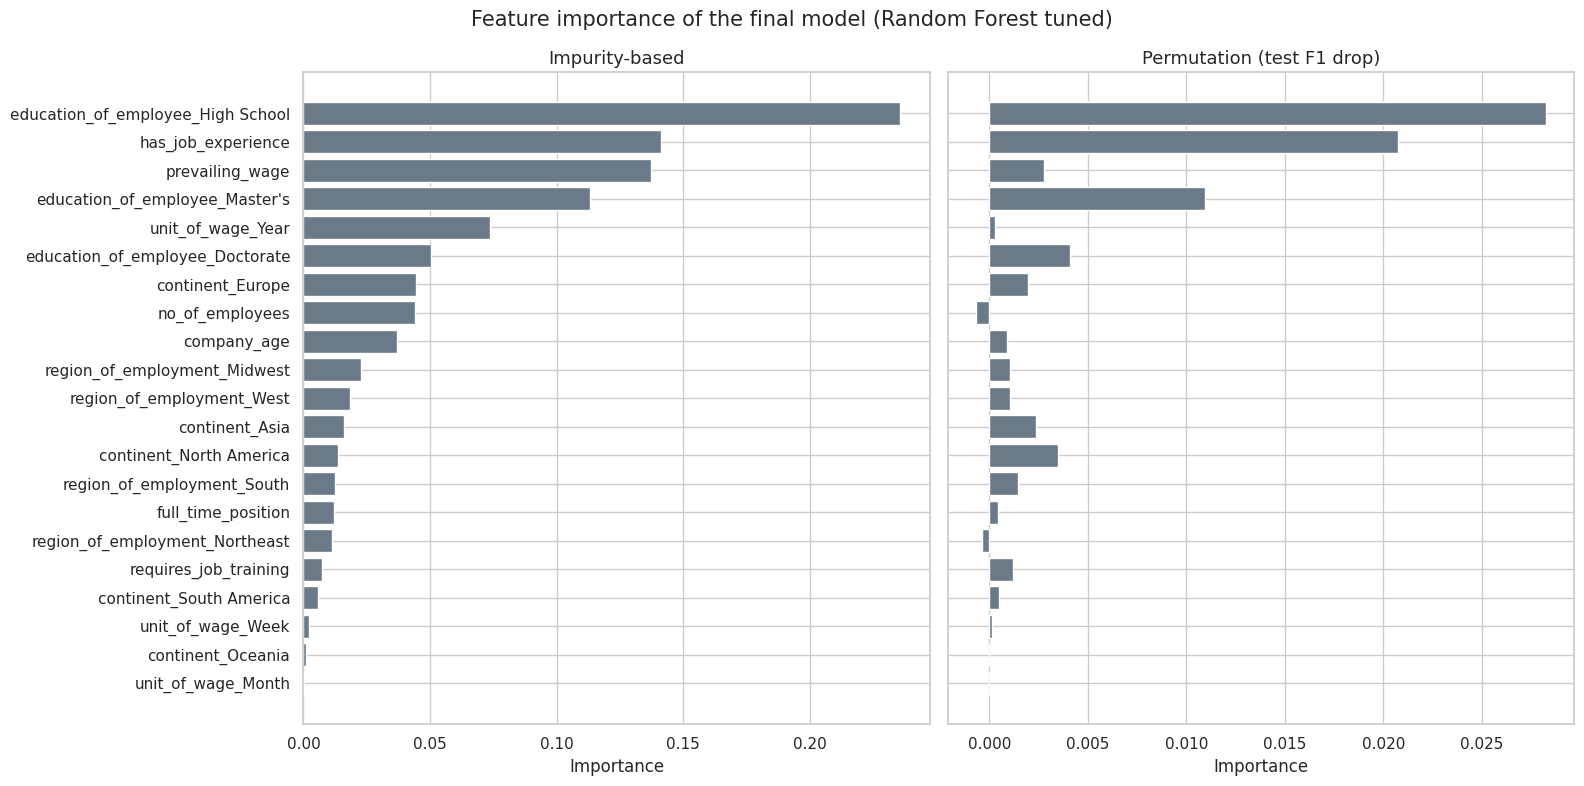

,Impurity-based,Permutation (test F1 drop)
education_of_employee_High School,0.236,0.028
has_job_experience,0.141,0.021
prevailing_wage,0.137,0.003
education_of_employee_Master's,0.113,0.011
unit_of_wage_Year,0.074,0.000
education_of_employee_Doctorate,0.050,0.004
continent_Europe,0.044,0.002
no_of_employees,0.044,-0.001
company_age,0.037,0.001
region_of_employment_Midwest,0.023,0.001


In [74]:
# Impurity-based importance of the final model
impurity_imp = pd.Series(final_model.feature_importances_, index=X_train.columns)

# Permutation importance on the test set (drop in F1 when a feature is shuffled, averaged over 10 repetitions)
perm = permutation_importance(final_model, X_test, y_test, scoring="f1", n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_test.columns)

importances = pd.DataFrame({"Impurity-based": impurity_imp, "Permutation (test F1 drop)": perm_imp})
importances = importances.sort_values("Impurity-based", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True)
for ax, col in zip(axes, importances.columns):
    ax.barh(importances.index, importances[col], color=NEUTRAL_COLOR)
    ax.set_title(col, fontsize=13)
    ax.set_xlabel("Importance")
axes[0].invert_yaxis()
fig.suptitle("Feature importance of the final model (Random Forest tuned)", fontsize=15)
plt.tight_layout()
plt.show()

importances.head(10)

**Observations**
* Both measures agree on the three most important drivers: **education (High School vs higher degrees)**, **job experience**, and **education (Master's)**. Doctorate and continent are also relevant.
* `prevailing_wage` and `unit_of_wage_Year` rank high on impurity importance but low on permutation importance. They carry largely the **same information** (very low wage values are the hourly wages), so when one is shuffled the model can still rely on the other; together they capture the hourly-wage effect found in the EDA.
* `no_of_employees`, `company_age`, `full_time_position`, and `requires_job_training` contribute very little on the test set, consistent with their weak relationships in the EDA.

### Direction of the effects (Logistic Regression coefficients)

The Random Forest shows **how much** each feature matters but not **in which direction**. The coefficients of the Logistic Regression (which generalizes almost as well) show whether each feature **increases or decreases** the odds of certification. Since the numerical features were standardized, their coefficients refer to a change of one standard deviation. For the dummy variables, the effect is relative to the reference category: Bachelor's (education), Hour (unit of wage), Island (region), and Africa (continent).

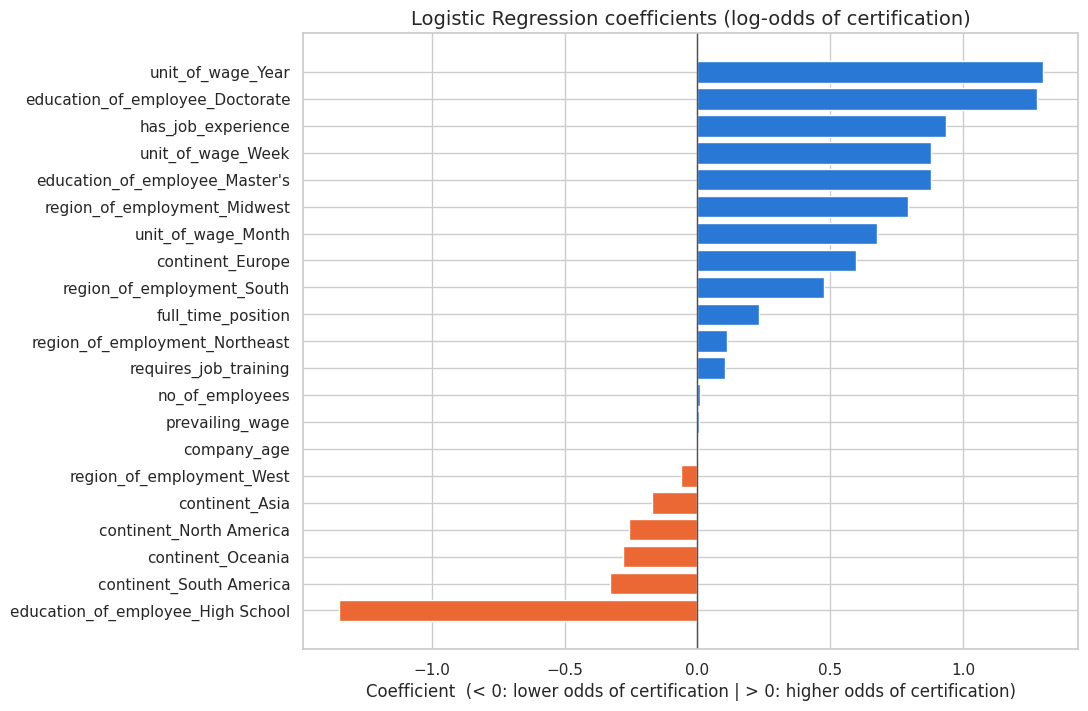

,Coefficient,Odds ratio
unit_of_wage_Year,1.300,3.671
education_of_employee_Doctorate,1.275,3.579
has_job_experience,0.936,2.549
unit_of_wage_Week,0.880,2.411
education_of_employee_Master's,0.877,2.403
region_of_employment_Midwest,0.792,2.208
unit_of_wage_Month,0.674,1.962
continent_Europe,0.597,1.817
region_of_employment_South,0.476,1.609
full_time_position,0.231,1.260


In [75]:
coefs = pd.DataFrame({"Coefficient": log_reg.coef_[0]}, index=X_train_scaled.columns)
coefs["Odds ratio"] = np.exp(coefs["Coefficient"])
coefs = coefs.sort_values("Coefficient")

# Blue = increases the odds of certification, orange = decreases them
colors = [STATUS_COLORS["Certified"] if c > 0 else STATUS_COLORS["Denied"] for c in coefs["Coefficient"]]
plt.figure(figsize=(10, 8))
plt.barh(coefs.index, coefs["Coefficient"], color=colors)
plt.axvline(0, color="#52514e", linewidth=1)
plt.title("Logistic Regression coefficients (log-odds of certification)", fontsize=14)
plt.xlabel("Coefficient  (< 0: lower odds of certification | > 0: higher odds of certification)")
plt.show()

coefs.sort_values("Coefficient", ascending=False)

**Observations**
* **Education** is the strongest factor in both directions: holding the other features constant, a High School applicant has about **0.26 times the odds** of certification of a Bachelor's applicant, while a Doctorate has **3.6 times** and a Master's **2.4 times** the odds.
* A **yearly wage** multiplies the odds of certification by **3.7** compared with an hourly wage (weekly and monthly wages also increase the odds).
* **Job experience** multiplies the odds by **2.5**.
* Employment in the **Midwest** (2.2×) and **South** (1.6×) increases the odds relative to the Island region; applicants from **Europe** have 1.8 times the odds of applicants from Africa, while applicants from South America, Oceania, North America, and Asia have lower odds.
* The coefficients of the standardized `prevailing_wage`, `no_of_employees`, and `company_age` are practically zero: once the other characteristics are known, the wage amount and the company's size and age do not change the odds.

### Applicant profiles and model confidence

In [76]:
# Certification rate of the applicant profiles identified in the EDA and the models (full dataset)
higher_degree = data["education_of_employee"].isin(["Master's", "Doctorate"])
experienced = data["has_job_experience"] == "Y"
yearly_wage = data["unit_of_wage"] == "Year"
high_school = data["education_of_employee"] == "High School"

profiles = {
    "Master's/Doctorate + experience + yearly wage": higher_degree & experienced & yearly_wage,
    "  ... and employed in the Midwest or South": higher_degree & experienced & yearly_wage
                                                  & data["region_of_employment"].isin(["Midwest", "South"]),
    "  ... and from Europe": higher_degree & experienced & yearly_wage & (data["continent"] == "Europe"),
    "High School + no job experience": high_school & ~experienced,
    "High School + hourly wage": high_school & (data["unit_of_wage"] == "Hour"),
    "All applications": pd.Series(True, index=data.index),
}

profile_table = pd.DataFrame(
    {
        "Applications": {name: mask.sum() for name, mask in profiles.items()},
        "Certification rate (%)": {name: 100 * data.loc[mask, "case_status"].eq("Certified").mean()
                                   for name, mask in profiles.items()},
    }
)
profile_table

,Applications,Certification rate (%)
Master's/Doctorate + experience + yearly wage,6529,90.504
... and employed in the Midwest or South,2855,96.007
... and from Europe,1090,93.853
High School + no job experience,1396,31.662
High School + hourly wage,395,24.810
All applications,25480,66.790


In [77]:
# How reliable are the predictions of the final model at different probability levels? (test set)
proba_certified = final_model.predict_proba(X_test)[:, 1]
tiers = pd.cut(proba_certified, bins=[0, 0.5, 0.8, 1.01], right=False,
               labels=["Low (< 0.5)", "Medium (0.5 - 0.8)", "High (>= 0.8)"])

tier_table = (
    pd.DataFrame({"tier": tiers, "certified": y_test.values})
    .groupby("tier", observed=True)["certified"]
    .agg(Applications="count", **{"Actually certified (%)": lambda s: 100 * s.mean()})
)
tier_table["Share of applications (%)"] = 100 * tier_table["Applications"] / len(y_test)
tier_table

,Applications,Actually certified (%),Share of applications (%)
tier,,,
Low (< 0.5),1799,33.852,23.535
Medium (0.5 - 0.8),3545,68.575,46.376
High (>= 0.8),2300,89.783,30.089


**Observations**
* The profiles combine the main drivers: **Master's/Doctorate applicants with job experience and a yearly wage** are certified **90.5%** of the time (6,529 applications), rising to **96.0%** when the job is in the Midwest or South and to **93.9%** for applicants from Europe.
* At the other extreme, **High School applicants without job experience** are certified only **31.7%** of the time, and **High School applicants paid hourly** only **24.8%**.
* The predicted probability of the final model is **well aligned with reality**: among the test applications with a probability of at least 0.8 (30% of the test set), **89.8% were actually certified**, while among those with a probability below 0.5 (23.5%), only 33.9% were certified. This makes the probability useful to **prioritize** the applications.

## **Conclusions and Business Recommendations**

### Key drivers of visa certification and denial

Both the EDA and the models point to the same drivers, in order of importance:

1. **Education of the employee (strongest driver).** The certification rate rises from 34.0% (High School) to 62.2% (Bachelor's), 78.6% (Master's), and 87.2% (Doctorate). High School is the most important feature of the final model and the first split of the decision tree.
2. **Job experience.** Experienced applicants are certified 74.5% of the time vs 56.1% without experience (2.5 times the odds). The benefit of experience grows with the education level.
3. **Unit of wage (how the job is paid).** Hourly-paid positions are certified only 34.6% of the time vs 69.9% for yearly salaries. The **amount** of the wage, on the other hand, has almost no effect once the unit is known.
4. **Region of employment and continent of the employee** (moderate effects). The Midwest (75.5%) and South (70.0%) have the highest certification rates; Europe (79.2%) is the continent with the highest rate and South America (57.9%) the lowest.
5. **Weak drivers:** company size, company age, full-time position, and job training barely change the probability of certification.

### Applicant profiles

| | Likely to be **certified** | Likely to be **denied** |
|---|---|---|
| Education | Master's or Doctorate | High School |
| Job experience | Has prior job experience | No prior job experience |
| Wage | Paid a yearly salary | Paid by the hour |
| Region / origin | Job in the Midwest or South; applicants from Europe | Job in the Northeast, West, or Island regions |
| Evidence | 90.5% certified (96.0% in the Midwest/South) | 31.7% certified (High School, no experience); 24.8% (High School, hourly wage) |

### Recommendations for OFLC and EasyVisa

1. **Use a three-tier triage based on the model's probability of certification:**
    * **High (≥ 0.8), ~30% of applications:** 89.8% of these cases were certified. They can go through a **faster, streamlined review** focused on confirming the documentation.
    * **Medium (0.5-0.8), ~46% of applications:** standard review.
    * **Low (< 0.5), ~24% of applications:** only 33.9% of these cases were certified. They should receive a **detailed review by experienced officers**, who can check the wage offered and the lack of available US workers in depth.

   This concentrates the officers' time where the risk of a wrong decision is highest and speeds up the processing of the strong cases.
2. **Require stronger supporting evidence for high-risk profiles.** Applications for **High School applicants without experience** and for **hourly-paid positions** have the lowest approval rates. EasyVisa should advise employers to document clearly why the position cannot be filled by US workers and to prefer salaried (yearly) offers when the role allows it.
3. **Advise employers on the profile of the candidates.** Candidates with a **Master's or Doctorate and prior job experience** have the highest chance of approval; EasyVisa can use this to help companies focus their international recruiting efforts and set realistic expectations for weaker profiles.
4. **Do not use the wage amount alone as a signal of approval.** Within the same unit of wage, higher wages do not increase the approval rate; what matters is that the position is salaried and that the offered wage meets the prevailing wage.
5. **Improve the data quality at the source.** Validate the unit of wage against the amount (weekly and monthly wages with yearly-scale values), reject negative numbers of employees, and collect additional information such as the occupation (SOC code), the offered wage vs the prevailing wage, and the job title, which would likely improve the model.

### How the model can support the certification process going forward

* The tuned Random Forest identifies **88.1% of the applications that deserve certification** with a precision of 76.9% (F1 = 0.821) on unseen data, and its predicted probabilities are well calibrated for prioritization. It is a reliable tool to **shortlist and rank** the applications and reduce the manual workload.
* The model should **support, not replace, the officers' decision**: it recognizes only 46.9% of the denied cases, so a final human review remains necessary, especially for the medium- and low-probability tiers.
* **Responsible use:** the model uses the applicant's **continent of origin**, which is a proxy for national origin. Before deploying it, OFLC should verify that this feature complies with anti-discrimination rules and consider **retraining without it**: the main drivers (education, experience, and unit of wage) do not depend on the applicant's origin. The model's performance and error rates should also be **monitored across groups** (continent, region, education) to make sure that it does not reinforce historical biases.
* The model should be **retrained periodically** (for example, every fiscal year) with new decisions, since the number of applications and the approval criteria change over time.

___